# PlasmaPy 核心公式与代码速通 (PlasmaPy 2026.2.0)

> 目标：用**最少的文字 + 最多的代码 + 公式驱动**的方式讲解 PlasmaPy 各子包的核心物理量。
> 每个小节 = 一个（组）公式（LaTeX）+ 一段可直接运行的代码。

约定：
- 所有量均带单位（`astropy.units`），光速 $c$ 取自 `astropy.constants`，**不要用** `u.c`。
- 公式符号与 PlasmaPy 源码 docstring 定义一致；量纲校验由 `validate_quantities` 自动完成。

## Part 0 — 基础与粒子

单位、常数、绘图约定，以及 `plasmapy.particles` 的粒子/原子数据接口。

### §0 环境与绘图样式

科研插图风格：衬线字体（Times New Roman）、字号 $\ge 18\,\mathrm{pt}$。

**注意**：首行 `%matplotlib inline` 让图直接内嵌到 notebook 单元格，不弹外部窗口。

In [1]:
%matplotlib inline
import numpy as np
import astropy.units as u
from astropy.constants import c, e, m_e, eps0, k_B, mu0
import astropy.constants as const

import matplotlib.pyplot as plt
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman"],
    "font.size": 18,
    "axes.labelsize": 18,
    "axes.titlesize": 18,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.fontsize": 16,
    "figure.dpi": 110,
})

import plasmapy
print("PlasmaPy", plasmapy.__version__)

PlasmaPy 2026.2.0


### §1 单位与常数换算

能量 $\leftrightarrow$ 温度（eV $\leftrightarrow$ K）：

$$E = k_B T \quad\Longleftrightarrow\quad T = \frac{E}{k_B}$$

用 `u.temperature_energy()` 等价关系实现自动换算。下面列出常用 CODATA 常数与若干无量纲组合常数。

基本常数与派生常数：

| 符号 | 公式 | 说明 |
|---|---|---|
| 玻尔半径 | $\displaystyle a_0 = \frac{4\pi\varepsilon_0\hbar^2}{m_e e^2}$ | Bohr radius |
| 经典电子半径 | $\displaystyle r_e = \frac{e^2}{4\pi\varepsilon_0 m_e c^2}$ | classical electron radius |
| 里德伯能量 | $\displaystyle E_R = \frac{m_e e^4}{8\varepsilon_0^2 h^2}$ | Rydberg energy |
| 精细结构常数 | $\displaystyle \alpha = \frac{e^2}{4\pi\varepsilon_0\hbar c}$ | fine-structure |
| 电子康普顿波长 | $\displaystyle \lambda_C = \frac{h}{m_e c}$ | Compton wavelength |
| 约化康普顿波长 | $\underline{\displaystyle \bar\lambda_C = \frac{\hbar}{m_e c}}$ | reduced Compton |
| 汤姆逊截面 | $\displaystyle \sigma_T = \frac{8\pi}{3} r_e^2$ | Thomson cross-section |
| 普朗克能量 | $\underline{\displaystyle E_P = \sqrt{\frac{\hbar c^5}{G}}}$ | Planck energy |

量纲关系：$\underline{\varepsilon_0 = \frac{1}{\mu_0 c^2}}$，$\underline{\hbar = \frac{h}{2\pi}}$，$\underline{k_B = 1.380\,649\times10^{-23}\,\mathrm{J/K}}$。

In [2]:
T_eV = 1.0 * u.keV
T_K  = T_eV.to(u.K, equivalencies=u.temperature_energy())
print("1 keV =", T_K)

E = (1e7 * u.K).to(u.eV, equivalencies=u.temperature_energy())
print("1e7 K =", E)

# 常数（裸数值）
print("c    =", c.si.value, "m/s")
print("m_e  =", m_e.si.value, "kg")
print("e    =", e.si.value, "C")
print("eps0 =", eps0.si.value)
print("mu0  =", mu0.si.value)
print("k_B  =", k_B.si.value)
print("h    =", const.h.si.value)
print("hbar =", const.hbar.si.value)

# 派生常数：用 SI 裸数值计算后再附单位，避免 astropy 多单位系统歧义
e_v = e.si.value
eps0_v = eps0.si.value
m_e_v = m_e.si.value
c_v = c.si.value
hbar_v = const.hbar.si.value
h_v = const.h.si.value

a0 = const.a0
ryd = const.Ryd
re = np.sqrt(e_v**2 / (4 * np.pi * eps0_v * m_e_v * c_v**2)) * u.m
alpha_fs = e_v**2 / (4 * np.pi * eps0_v * hbar_v * c_v)
lamC = (h_v / (m_e_v * c_v)) * u.m
sigmaT = (8 * np.pi / 3 * re.value**2) * u.m**2
print("\nBohr radius a0      =", a0)
print("classical e- radius =", re)
print("Rydberg energy      =", ryd)
print("fine-structure a    =", alpha_fs)
print("Compton wavelength  =", lamC)
print("Thomson cross-sec   =", sigmaT)

1 keV = 11604518.121550081 K
1e7 K = 861.7333262145178 eV
c    = 299792458.0 m/s
m_e  = 9.1093837139e-31 kg
e    = 1.602176634e-19 C
eps0 = 8.8541878188e-12
mu0  = 1.25663706127e-06
k_B  = 1.380649e-23
h    = 6.62607015e-34
hbar = 1.0545718176461565e-34

Bohr radius a0      =   Name   = Bohr radius
  Value  = 5.29177210544e-11
  Uncertainty  = 8.2e-21
  Unit  = m
  Reference = CODATA 2022
classical e- radius = 5.30842756422228e-08 m
Rydberg energy      =   Name   = Rydberg constant
  Value  = 10973731.568157
  Uncertainty  = 1.2e-05
  Unit  = 1 / m
  Reference = CODATA 2022
fine-structure a    = 0.007297352564333013
Compton wavelength  = 2.426310235380317e-12 m
Thomson cross-sec   = 2.360752162402666e-14 m2


### §2 粒子与原子数据

`Particle` 封装一个粒子；`periodic_table_*`、`atomic_number` 给出周期表信息；
`ParticleList` / `CustomParticle` 处理粒子集合与自定义粒子。

原子/核数据公式：

| 量 | 公式 |
|---|---|
| 约化质量 | $\displaystyle \mu = \frac{m_1 m_2}{m_1 + m_2}$ |
| 质量数 | $\underline{\displaystyle A = Z + N}$ |
| 同位素质量数 | $\underline{\displaystyle m_A \approx A\,m_u}$ |
| 结合能（半经验质量公式） | $\underline{\displaystyle B(A,Z) = a_V A - a_S A^{2/3} - a_C \frac{Z^2}{A^{1/3}} - a_A\frac{(A-2Z)^2}{A}}$ |
| 玻尔磁子 | $\underline{\displaystyle \mu_B = \frac{e\hbar}{2m_e}}$ |
| 核磁子 | $\underline{\displaystyle \mu_N = \frac{e\hbar}{2m_p}}$ |

In [3]:
from plasmapy.particles import (
    Particle, ParticleList, CustomParticle, reduced_mass,
)
from plasmapy.particles.atomic import (
    periodic_table_block, periodic_table_category,
    periodic_table_group, periodic_table_period, atomic_number,
)

p = Particle("p+")
print("proton  :", p)
print("mass    =", p.mass)
print("charge  =", p.charge)
print("symbol  =", p.symbol, " Z =", p.charge_number)

# 周期表查询（2026.2.0 起位于 plasmapy.particles.atomic）
print("\nFe block    =", periodic_table_block("Fe"))     # 'd' 而非 'd-block'
print("Fe category =", periodic_table_category("Fe"))
print("Fe group    =", periodic_table_group("Fe"))
print("Fe period   =", periodic_table_period("Fe"))
print("Fe Z        =", atomic_number("Fe"))

# 约化质量、同位素、结合能
mu_red = reduced_mass("p+", "e-")
print("\nreduced mass (p+, e-) =", mu_red)
D = Particle("D")
print("D mass                =", D.mass)
print("Fe-56 nuclide mass    =", Particle("Fe-56").nuclide_mass)

# 粒子集合与自定义粒子
pl = ParticleList(["e-", "p+"])
print("\nParticleList charges :", pl.charge_number)

cp = CustomParticle(mass=1.67e-27 * u.kg, charge=1.6e-19 * u.C)
print("CustomParticle Z    :", cp.charge_number)

proton  : p+
mass    = 1.67262192595e-27 kg
charge  =   Name   = Electron charge
  Value  = 1.602176634e-19
  Uncertainty  = 0.0
  Unit  = C
  Reference = CODATA 2022
symbol  = p+  Z = 1

Fe block    = d
Fe category = transition metal
Fe group    = 8
Fe period   = 4
Fe Z        = 26

reduced mass (p+, e-) = 9.10442528891677e-31 kg
D mass                = 3.3444946913495014e-27 kg
Fe-56 nuclide mass    = 9.285846269586154e-26 kg

ParticleList charges : [-1  1]
CustomParticle Z    : 0.998641451913722


### §3 电离态与电离态集合

`IonizationState` 描述单一元素各电荷态占比；`IonizationStateCollection` 描述多种元素。
注意：密度参数名为 `n_elem`（单元素）/ `n0`（集合），不是 `n`。

$$f_j = \frac{n_j}{n_{\rm elem}},\qquad Z_{\rm mean} = \sum_j j\,f_j,\qquad \sum_j f_j = 1$$

In [4]:
from plasmapy.particles import IonizationState, IonizationStateCollection

# 单一元素：显式给出离子分数（He 有 0,1,2 三态）
st = IonizationState("He", ionic_fractions=[0.1, 0.6, 0.3], n_elem=1e19 * u.m**-3, T_e=1e5 * u.K)
print("He charge_numbers :", st.charge_numbers)        # [0 1 2]
print("He ionic_fraction :", st.ionic_fractions)
print("He Z_mean         :", st.Z_mean)

# 多元素集合
col = IonizationStateCollection(
    {"H": [1, 0], "He": [0.2, 0.5, 0.3]},
    T_e=1e4 * u.K, n0=1e19 * u.m**-3,
)
print("\nCollection n0        :", col.n0)
print("Collection H frac    :", col.ionic_fractions["H"])
print("Collection He frac   :", col.ionic_fractions["He"])

He charge_numbers : [0 1 2]
He ionic_fraction : [0.1 0.6 0.3]
He Z_mean         : 1.2

Collection n0        : 1e+19 1 / m3
Collection H frac    : [1. 0.]
Collection He frac   : [0.2 0.5 0.3]


## Part I — 特征量

频率、长度、速度、密度/漂移、介电张量等只依赖局部参数的标量化特征量。

### §4 特征频率（公式表）

| 量 | 公式 |
|---|---|
| 等离子体频率 | $\displaystyle \omega_p = \sqrt{\frac{n\,|q|}{\varepsilon_0 m}} = \sqrt{\frac{n_e e^2}{\varepsilon_0 m_e}}$ |
| 电子/离子等离子频率 | $\displaystyle \omega_{pe} = \sqrt{\frac{n_e e^2}{\varepsilon_0 m_e}},\quad \omega_{pi} = \sqrt{\frac{n_i Z^2 e^2}{\varepsilon_0 m_i}}$ |
| 角频率 $\leftrightarrow$ 频率 | $\underline{\displaystyle \omega = 2\pi f,\quad f = \omega/2\pi}$ |
| 回旋频率（拉莫尔） | $\displaystyle \omega_c = \frac{|Z|\,e\,B}{m}$ |
| 电子/离子回旋频率 | $\displaystyle \omega_{ce} = \frac{eB}{m_e},\quad \omega_{ci} = \frac{ZeB}{m_i}$ |
| 上混杂频率 | $\displaystyle \omega_{uh}^2 = \omega_{pe}^2 + \omega_{ce}^2$ |
| 下混杂频率 | $\displaystyle \frac{1}{\omega_{lh}^2} = \frac{1}{\omega_{ci}^2+\omega_{pi}^2} + \frac{1}{\omega_{ci}\omega_{ce}}$ |
| Buchsbaum（双离子）频率 | $\displaystyle \omega_{\pm}^2 = \frac{1}{2}\Omega_1^2\!\left(1\pm\sqrt{1-\frac{4\Omega_1^2\Omega_2^2\sin^2\theta}{(\Omega_1^2+\Omega_2^2)^2}}\right)$ |
| 截止频率（O 模） | $\underline{\displaystyle \omega_{R,L} = \frac{1}{2}\!\left(\omega_{ce}\pm\sqrt{\omega_{ce}^2+4\omega_p^2}\right)}$ |
| 截止频率（X 模） | $\underline{\displaystyle \omega_X^2 = \omega_{pe}^2 + \frac{1}{2}\omega_{ce}^2}$ |
| 等离子体周期 | $\underline{\displaystyle \tau_p = 2\pi/\omega_p}$ |
| 回旋周期 | $\underline{\displaystyle \tau_c = 2\pi/\omega_c}$ |

In [5]:
from plasmapy.formulary import (
    plasma_frequency, gyrofrequency, upper_hybrid_frequency, lower_hybrid_frequency,
)
from plasmapy.formulary.frequencies import Buchsbaum_frequency
n_e = 1e19 * u.m**-3

# 电子等离子体频率 (rad/s)
wp_e = plasma_frequency(n_e, particle="e-")
print("electron plasma frequency :", wp_e)
print("  -> in Hz               :", wp_e.to(u.Hz, equivalencies=[(u.cy / u.s, u.Hz)]))

# 质子回旋频率
wc_p = gyrofrequency(0.1 * u.T, "p+")
print("\nproton gyrofrequency     :", wc_p)

# 上混杂频率 (电子等离子体 + 电子回旋)
wuh = upper_hybrid_frequency(B=0.1 * u.T, n_e=n_e)
print("\nupper hybrid frequency   :", wuh)

# 下混杂频率 (需离子种类与密度)
wlh = lower_hybrid_frequency(B=0.1 * u.T, n_i=n_e, ion="D+")
print("lower hybrid frequency   :", wlh)

# 离子等离子体频率（Deuterium）
wpi = plasma_frequency(n_e, particle="D+")
print("\nD+ plasma frequency      :", wpi)
# 电子回旋 (负 sign convention 取绝对值)
wce = gyrofrequency(0.1 * u.T, "e-")
print("electron gyrofrequency   :", wce)

# Buchsbaum 双离子混杂频率（两种离子）
wb = Buchsbaum_frequency(B=0.1*u.T, ion1="He+", ion2="D+", n1=0.5*n_e, n2=0.5*n_e)
print("\nBuchsbaum freq (two-ion):", wb)

# 角频率 -> Hz 互转（用 .to 等价关系）
f_hz = wp_e.to(u.Hz, equivalencies=[(u.cy / u.s, u.Hz)])
print("wp in Hz via .to        :", f_hz)

electron plasma frequency : 178398636416.04175 rad / s
  -> in Hz               : 28393024826.466854 Hz

proton gyrofrequency     : 9578833.143000986 rad / s

upper hybrid frequency   : 179263544139.04166 rad / s
lower hybrid frequency   : 288907852.9824542 rad / s

D+ plasma frequency      : 2944624544.2134686 rad / s
electron gyrofrequency   : 17588200083.779984 rad / s

Buchsbaum freq (two-ion): 3398899.3411862305 rad / s
wp in Hz via .to        : 28393024826.466854 Hz


### §5 特征长度（公式表）

| 量 | 公式 |
|---|---|
| Debye 长度 | $\displaystyle \lambda_D = \sqrt{\frac{\varepsilon_0 k_B T_e}{n_e e^2}}$ |
| 电子/离子 Debye 长度 | $\underline{\displaystyle \lambda_{De} = \sqrt{\frac{\varepsilon_0 k_B T_e}{n_e e^2}},\quad \lambda_{Di} = \sqrt{\frac{\varepsilon_0 k_B T_i}{n_i Z^2 e^2}}}$ |
| 回旋半径（相对论） | $\displaystyle r_{L,s} = \frac{\gamma\,m_s v_{\perp,s}}{|q_s|\,B}$ |
| 热回旋半径 | $\displaystyle r_{L,th} = \frac{\sqrt{2k_B T_s/m_s}}{\omega_{c,s}}$ |
| 惯性长度（skin depth） | $\displaystyle d_s = \frac{c}{\omega_{p,s}}$ |
| 电子/离子惯性长度 | $\displaystyle d_e = \frac{c}{\omega_{pe}},\quad d_i = \frac{c}{\omega_{pi}}$ |
| 碰撞less 趋肤深度 | $\underline{\displaystyle \delta_s = \sqrt{\frac{2\eta}{\mu_0\omega}}}$ |
| 热 Larmor 半径（含温度） | $\underline{\displaystyle \rho_s = \sqrt{\frac{2 k_B T_s}{m_s}}\,\frac{1}{\omega_{c,s}}}$ |
| Debye 球半径 | $\underline{\displaystyle r_D = \lambda_D}$ |
| 离子声速相关长度 | $\underline{\displaystyle L_s = c_s/\omega_{pi}}$ |

In [6]:
from plasmapy.formulary import Debye_length, gyroradius, inertial_length
T_e = 1e6 * u.K
n_e = 1e19 * u.m**-3

lambda_D = Debye_length(T_e, n_e)
print("Debye length      :", lambda_D)

# 质子在 T=1e6 K 下的热回旋半径（默认含相对论修正）
rL = gyroradius(B=0.2 * u.T, particle="p+", T=T_e)
print("proton gyroradius :", rL)

# 电子惯性长度
d_e = inertial_length(n_e, "e-")
print("electron skin depth:", d_e)

# 离子惯性长度（Deuterium）
d_i = inertial_length(n_e, "D+")
print("ion skin depth (D+):", d_i)

# 电子回旋半径（电子）
rLe = gyroradius(B=0.2 * u.T, particle="e-", T=T_e)
print("electron gyroradius:", rLe)

Debye length      : 2.1822555802126225e-05 m
proton gyroradius : 0.006706797324705982 m
electron skin depth: 0.0016804638422283503 m
ion skin depth (D+): 0.10181007917940751 m
electron gyroradius: 0.00015654312469647904 m


### §6 特征速度（公式表）

热速度通用式：$\displaystyle v_{th} = C_0 \sqrt{\frac{k_B T}{m}}$ ，系数 $C_0$ 取决于 `method` 与维数 $d$：

| method ↓ / ndim → | 1 | 2 | 3 |
|---|---|---|---|
| `most_probable` | 0 | 1 | $\sqrt{2}$ |
| `rms` | 1 | $\sqrt{2}$ | $\sqrt{3}$ |
| `mean_magnitude` | $\sqrt{2/\pi}$ | $\sqrt{\pi/2}$ | $\sqrt{8/\pi}$ |

其它速度尺度：

- Alfvén 速度： $\displaystyle V_A = \frac{B}{\sqrt{\mu_0 \rho}}$ ， $\rho = n_i m_i + n_e m_e$
- 离子声速： $\displaystyle V_S = \sqrt{\frac{\gamma_e Z k_B T_e + \gamma_i k_B T_i}{m_i\,(1+k^2\lambda_D^2)}}$
- κ 热速度： $\displaystyle v_{th,\kappa} = \sqrt{\frac{\kappa-3/2}{\kappa}\,\frac{2k_B T}{m}}$
- 相对论热速度： $\underline{\displaystyle v_{th} \to c\,\sqrt{1-\frac{1}{\gamma_{th}^2}}}$
- 漂移速度（ExB）： $\underline{\displaystyle v_{dr} = E/B}$
- 特征碰撞速度： $\underline{\displaystyle v_{coll} \sim \sqrt{\frac{k_B T}{m}}}$

In [7]:
from plasmapy.formulary import thermal_speed, Alfven_speed, ion_sound_speed
from plasmapy.formulary.speeds import thermal_speed_coefficients
from plasmapy.formulary.distribution import kappa_thermal_speed
T = 1e6 * u.K

# 三种定义的热速度（质子，3D）
for method in ("most_probable", "rms", "mean_magnitude"):
    v = thermal_speed(T, "p+", method=method, ndim=3)
    print(f"v_th({method:14s}) =", v)

# 热速度系数 C0
print("\nC0 (rms,3)   =", thermal_speed_coefficients("rms", 3))
print("C0 (mp,1)    =", thermal_speed_coefficients("most_probable", 1))

# Alfvén 速度（质子、数密度给出离子种类）
VA = Alfven_speed(B=0.014 * u.T, density=5e19 * u.m**-3, ion="p+")
print("\nAlfven speed :", VA)

# 离子声速（非色散极限 k->0）
cs = ion_sound_speed(T_e=5e6 * u.K, T_i=0 * u.K, ion="p+", gamma_e=1, gamma_i=3)
print("ion sound speed :", cs)

# kappa 热速度（kappa=2）
vth_k = kappa_thermal_speed(T, 2, "e-")
print("\nkappa thermal speed (k=2) :", vth_k)

v_th(most_probable ) = 128486.57319402759 m / s
v_th(rms           ) = 157363.2715620653 m / s
v_th(mean_magnitude) = 144981.57244363346 m / s

C0 (rms,3)   = 1.7320508075688772
C0 (mp,1)    = 0

Alfven speed : 43173.869937717565 m / s
ion sound speed : 203155.11002153135 m / s

kappa thermal speed (k=2) : 2752847.4494895455 m / s


### §7 密度与漂移速度（公式表）

- 质量密度： $\displaystyle \rho = n\,m$
- 数密度 $\leftrightarrow$ 质量密度： $\underline{\displaystyle n = \rho/m}$
- 临界密度： $\displaystyle n_c = \frac{m_e\varepsilon_0\omega^2}{e^2} = \frac{\varepsilon_0}{e^2}\left(\frac{2\pi c}{\lambda}\right)^2$
- $\mathbf{E}\times\mathbf{B}$ 漂移（与电荷/质量无关）： $\displaystyle \vec v_{E\times B}=\frac{\vec E\times\vec B}{B^2}$
- 抗磁漂移： $\displaystyle \vec v_{\nabla p}=\frac{\nabla p\times\vec B}{q\,n\,B^2}$
- 力漂移： $\displaystyle \vec v_F = \frac{\vec F\times\vec B}{q\,B^2}$
- 极化漂移： $\underline{\displaystyle \vec v_p = \frac{m}{q\,B^2}\frac{d\vec E_\perp}{dt}}$
- 总漂移速度（含质量依赖）： $\underline{\displaystyle v_{dr,s} = \frac{E}{B}}$

In [8]:
from plasmapy.formulary.densities import mass_density, critical_density
from plasmapy.formulary.drifts import ExB_drift, diamagnetic_drift, force_drift
from plasmapy.particles import Particle
from plasmapy.formulary.laser import em_angular_frequency

rho = mass_density(1e28 * u.m**-3, "p+")
print("mass density (n=1e28, p+) :", rho)

# 临界密度（0.351 micron 激光）
lam = 0.351 * u.um
nc = critical_density(em_angular_frequency(lam))
print("critical density (0.351 um) :", nc)

# E×B 漂移：E, B 必须传矢量（Quantity 数组）
E = np.array([1e3, 0, 0]) * u.V / u.m
B = np.array([0, 0, 0.1]) * u.T
vEB = ExB_drift(E, B)
print("\nE x B drift :", vEB, " (沿 +y)")

# 抗磁漂移：dp 为压力梯度，q 为粒子电荷
dp = np.array([1e-3, 0, 0]) * u.Pa / u.m
q  = Particle("p+").charge
vdia = diamagnetic_drift(dp, B, n=1e19 * u.m**-3, q=q)
print("diamagnetic drift :", vdia)

# 力漂移（电场力 qE 等效为 F）
F = q * E
vF = force_drift(F, B, q=q)
print("force drift       :", vF)

mass density (n=1e28, p+) : 16.7262192595 kg / m3
critical density (0.351 um) : 9.049067933253333e+27 1 / m3

E x B drift : [     0. -10000.      0.] m / s  (沿 +y)
diamagnetic drift : [-0.          0.00624151 -0.        ] m / s
force drift       : [     0. -10000.      0.] m / s


### §8 冷/热等离子体介电张量（公式表）

Stix 表象（$B \parallel \hat z$，$\exp(-i\omega t)$）：

$$\varepsilon = \varepsilon_0
\begin{pmatrix}
S & -iD & 0\\
+iD & S & 0\\
0 & 0 & P
\end{pmatrix},\qquad
\begin{aligned}
S &= 1 - \sum_s \frac{\omega_{p,s}^2}{\omega^2-\Omega_{c,s}^2}\\
D &= \sum_s \frac{\Omega_{c,s}}{\omega}\frac{\omega_{p,s}^2}{\omega^2-\Omega_{c,s}^2}\\
P &= 1 - \sum_s \frac{\omega_{p,s}^2}{\omega^2}
\end{aligned}$$

旋转（LRP）表象对角化，元素 $L,R,P$：

$$L = 1 - \sum_s \frac{\omega_{p,s}^2}{\omega(\omega+\Omega_{c,s})},\quad
R = 1 - \sum_s \frac{\omega_{p,s}^2}{\omega(\omega-\Omega_{c,s})},\quad
P = 1 - \sum_s \frac{\omega_{p,s}^2}{\omega^2}$$

热等离子体用 `permittivity_1D_Maxwellian`（含 $\varepsilon(\omega,k)$ 修正）：

$$\varepsilon(\omega,k) = 1 + \frac{k_D^2}{k^2}\left[1 + i\sqrt{\pi}\,\zeta\,Z(\zeta)\right],\qquad \zeta=\frac{\omega}{k\,v_{th}}$$

In [9]:
from plasmapy.formulary.dielectric import (
    cold_plasma_permittivity_SDP, cold_plasma_permittivity_LRP, permittivity_1D_Maxwellian,
    plasma_dispersion_func_deriv,
)
B = 2 * u.T
species = ["e-", "D+"]
n = [1e18 * u.m**-3, 1e18 * u.m**-3]
omega = 3.7e9 * 2 * np.pi * u.rad / u.s

# SDP 表象 -> 命名元组 (sum, difference, plasma)
sdp = cold_plasma_permittivity_SDP(B, species, n, omega)
print("S (sum)     =", sdp.sum)
print("D (diff)    =", sdp.difference)
print("P (plasma)  =", sdp.plasma)

# LRP 表象 -> 命名元组 (left, right, plasma)
lrp = cold_plasma_permittivity_LRP(B, species, n, omega)
print("\nL (left)    =", lrp.left)
print("R (right)   =", lrp.right)
print("P (plasma)  =", lrp.plasma)

# 热等离子体一维介电（电子，含动能修正）
omega_th = 1e11 * u.rad / u.s
k_th = 1e4 * u.rad / u.m
eps_th = permittivity_1D_Maxwellian(omega_th, kWave=k_th, T=1e4 * u.K, n=1e19 * u.m**-3, particle="e-")
print("\nhot epsilon (real part) =", eps_th.value.real)
print("hot epsilon (imag part) =", eps_th.value.imag)

S (sum)     = 1.0242290176263869
D (diff)    = 0.3908935276969467
P (plasma)  = -4.890310394984158

L (left)    = 0.6333354899294401
R (right)   = 1.4151225453233334
P (plasma)  = -4.890310394984158

hot epsilon (real part) = -3.1971891927773957
hot epsilon (imag part) = 3.617250169654893e-139


## Part II — 分布、辐射、激光、量子简并与相对论

### §9 麦克斯韦分布与 κ 速度分布（公式表）

1D 速度分布：

$$f(v) = \sqrt{\frac{m}{2\pi k_B T}}\,\exp\!\left[-\frac{m(v-V_{dr})^2}{2k_B T}\right]
\equiv \frac{1}{\sqrt{\pi v_{Th}^2}}\,\exp\!\left[-\frac{(v-v_{dr})^2}{v_{Th}^2}\right]$$

3D 速率分布：

$$f(v)\,dv = 4\pi v^2 \left(\frac{m}{2\pi k_B T}\right)^{3/2}\exp\!\left(-\frac{mv^2}{2k_B T}\right) dv$$

2D、3D 速度分布与 1D/2D/3D 速率分布：

$$f_{3D}(\vec v) = \left(\frac{m}{2\pi k_B T}\right)^{3/2}\exp\!\left(-\frac{m|\vec v|^2}{2k_B T}\right)$$

κ 速度分布（超热尾巴，$\kappa\to\infty$ 退化为麦克斯韦）：

$$f_\kappa(v) = \frac{\Gamma(\kappa+1)}{\Gamma(\kappa-1/2)}\frac{1}{\sqrt{\pi(\kappa-3/2)}\theta}\left[1+\frac{(v-v_0)^2}{(\kappa-3/2)\theta^2}\right]^{-(\kappa+1)}$$

$$\theta = \sqrt{\frac{2k_B T}{m}},\qquad \langle v^2\rangle_\kappa = \frac{\kappa-3/2}{\kappa-5/2}\,\theta^2$$

Maxwellian_velocity_2D (s^2/m^2) = [1.03290949e-13] s2 / m2
Maxwellian_velocity_3D (s^3/m^3) = [3.24923219e-20] s3 / m3
kappa_velocity_3D    (s^3/m^3) = [1.66632155e-19] s3 / m3


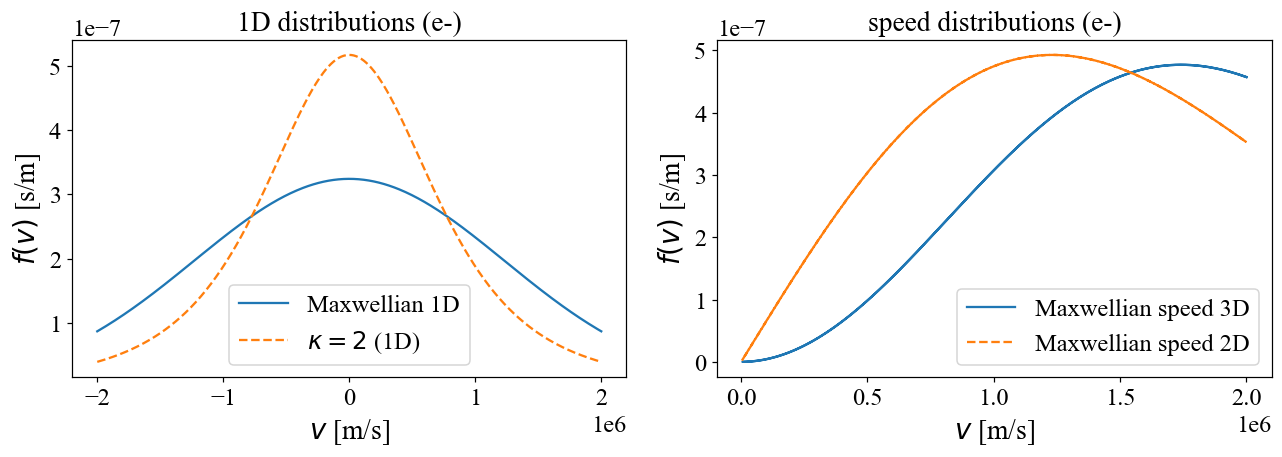

In [10]:
from plasmapy.formulary.distribution import (
    Maxwellian_1D, Maxwellian_speed_1D, Maxwellian_speed_2D, Maxwellian_speed_3D,
    Maxwellian_velocity_2D, Maxwellian_velocity_3D,
    kappa_velocity_1D, kappa_velocity_3D, kappa_thermal_speed,
)
T = 1e5 * u.K
v = np.linspace(-2e6, 2e6, 400) * u.m / u.s
vpos = np.abs(v)

# 1D / 2D / 3D 速率 (speed) 分布 —— 单位均为 s/m
f1 = Maxwellian_1D(v, T=T, particle="e-")
f2s = Maxwellian_speed_2D(vpos, T=T, particle="e-")
f3s = Maxwellian_speed_3D(vpos, T=T, particle="e-")
fk = kappa_velocity_1D(v, T=T, particle="e-", kappa=2)

# 2D / 3D 速度分布（网格点，单位分别为 s^2/m^2 与 s^3/m^3，仅作标量示例）
vx = np.array([1e5]) * u.m / u.s; vy = np.array([2e5]) * u.m / u.s; vz = np.array([3e5]) * u.m / u.s
f2d = Maxwellian_velocity_2D(vx, vy, T=T, particle="e-")
f3d = Maxwellian_velocity_3D(vx, vy, vz, T=T, particle="e-")
fk3 = kappa_velocity_3D(vx, vy, vz, T=T, kappa=2)
print("Maxwellian_velocity_2D (s^2/m^2) =", f2d)
print("Maxwellian_velocity_3D (s^3/m^3) =", f3d)
print("kappa_velocity_3D    (s^3/m^3) =", fk3)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(v.to(u.m / u.s).value, f1.to(u.s / u.m).value, label="Maxwellian 1D")
ax[0].plot(v.to(u.m / u.s).value, fk.to(u.s / u.m).value, "--", label=r"$\kappa=2$ (1D)")
ax[0].set_xlabel(r"$v$ [m/s]"); ax[0].set_ylabel(r"$f(v)$ [s/m]")
ax[0].set_title("1D distributions (e-)"); ax[0].legend()
ax[1].plot(vpos.to(u.m / u.s).value, f3s.to(u.s / u.m).value, label="Maxwellian speed 3D")
ax[1].plot(vpos.to(u.m / u.s).value, f2s.to(u.s / u.m).value, "--", label="Maxwellian speed 2D")
ax[1].set_xlabel(r"$v$ [m/s]"); ax[1].set_ylabel(r"$f(v)$ [s/m]")
ax[1].set_title("speed distributions (e-)"); ax[1].legend()
plt.tight_layout(); plt.show()

### §10 激光参数与临界密度（公式表）

| 量 | 公式 |
|---|---|
| 角频率 ← 波长 | $\displaystyle \omega = \frac{2\pi c}{\lambda}$ |
| 波长 ← 角频率 | $\displaystyle \lambda = \frac{2\pi c}{\omega}$ |
| 电场幅值 ← 强度 | $\displaystyle E_0 = \sqrt{\frac{2I}{c\varepsilon_0}}$ |
| 强度 ← 电场 | $\displaystyle I = \frac{1}{2}c\varepsilon_0 E_0^2$ |
| 归一化矢势 | $\displaystyle a_0 = \frac{e E_0}{m_e\omega c} = \frac{e\lambda}{m_e\pi}\sqrt{\frac{I}{2\varepsilon_0 c^5}}$ |
| 临界密度 | $\displaystyle n_c = \frac{m_e\varepsilon_0\omega^2}{e^2}$ |
| 有质动力 | $\displaystyle p_{pond} = \frac{I}{c}(1+R) \approx \frac{I}{c}$ |
| 高斯束腰半径 ← FWHM | $\displaystyle w_0 = \frac{\mathrm{FWHM}}{\sqrt{2\ln 2}}$ |
| FWHM ← 束腰半径 | $\displaystyle \mathrm{FWHM} = \sqrt{2\ln 2}\,w_0$ |
| 瑞利长度 | $\displaystyle z_R = \frac{\pi w_0^2}{\lambda}$ |
| 高斯功率 | $\displaystyle P = I\,\pi w_0^2$ |
| 相对论临界密度修正 | $\displaystyle n_c^{\rm rel} = (1+a_0^2/2)\,n_c$ |
| 振荡电子能量（非相对论） | $\displaystyle U_{osc} = \frac{1}{4}m_e \omega^2 a_0^2 (c/\omega)^2 = \frac{a_0^2}{4}m_e c^2$ |

In [11]:
from plasmapy.formulary.laser import (
    em_angular_frequency, em_wavelength, electric_field_amplitude,
    normalized_vector_potential, intensity,
    Gaussian_Rayleigh_length, Gaussian_beam_waist_radius,
    Gaussian_spot_size_FWHM, Gaussian_power,
)
from plasmapy.formulary.densities import critical_density
lam = 0.351 * u.um                 # 0.351 micron
I = 5e14 * u.W / u.cm**2           # 5e14 W/cm^2

omega = em_angular_frequency(lam)
lam_back = em_wavelength(omega)
E0 = electric_field_amplitude(I)
a0 = normalized_vector_potential(I, lam)
nc = critical_density(omega)

print("angular frequency :", omega)
print("wavelength (back) :", lam_back)
print("E0               :", E0)
print("a0               :", a0)
print("critical density :", nc)

# 往返校验：I(E0) 应等于原始 I
print("I from E0        :", intensity(E0))

# 高斯光束几何
w0 = Gaussian_beam_waist_radius(35.4 * u.um)     # FWHM -> waist
zR = Gaussian_Rayleigh_length(lam, w0)
P  = Gaussian_power(I, w0)
fwhm = Gaussian_spot_size_FWHM(w0)
print("\nbeam waist w0    :", w0)
print("Rayleigh length  :", zR)
print("Gaussian power   :", P)
print("FWHM (back)      :", fwhm)

angular frequency : 5366528681791606.0 rad / s
wavelength (back) : 3.509999999999999e-07 m
E0               : 61378360471.06344 V / m
a0               : 0.00671000004710824
critical density : 9.049067933253333e+27 1 / m3
I from E0        : 5e+18 W / m2

beam waist w0    : 3.0065991730195874e-05 m
Rayleigh length  : 0.008090843924974596 m
Gaussian power   : 7099715544.165208 W
FWHM (back)      : 3.54e-05 m


### §11 量子简并与简并参数（公式表）

当电子数密度极高时经典近似失效，引入费米能与简并参数：

$$E_F = \frac{\hbar^2}{2m_e}(3\pi^2 n_e)^{2/3},\qquad
\theta = \frac{k_B T_e}{E_F},\qquad
\lambda_{TF} = \sqrt{\frac{\varepsilon_0 \hbar^2}{m_e e^2 n_e^{1/3}}}$$

更多量子量：

| 量 | 公式 |
|---|---|
| 费米温度 | $\underline{\displaystyle T_F = E_F/k_B}$ |
| 费米波矢 | $\underline{\displaystyle k_F = (3\pi^2 n_e)^{1/3}}$ |
| 费米速度 | $\underline{\displaystyle v_F = \hbar k_F/m_e = \sqrt{2E_F/m_e}}$ |
| 热德布罗意波长 | $\displaystyle \lambda_{th} = \frac{h}{\sqrt{2\pi m_e k_B T_e}}$ |
| 德布罗意波长 | $\displaystyle \lambda_{dB} = \frac{h}{m v}$ |
| Wigner–Seitz 半径 | $\displaystyle r_s = \left(\frac{3}{4\pi n_e}\right)^{1/3}$ |
| 化学势（简并） | $\displaystyle \mu \approx E_F\left[1-\frac{\pi^2}{12}\theta^2\right]$ |
| 耦合参数 | $\underline{\displaystyle \Gamma = \frac{e^2}{4\pi\varepsilon_0 a k_B T}}$ |

$\theta\ll 1$ 为简并（量子）区，$\theta\gg 1$ 为经典区。

In [12]:
from plasmapy.formulary.quantum import (
    Fermi_energy, Thomas_Fermi_length, chemical_potential, quantum_theta,
    deBroglie_wavelength, thermal_deBroglie_wavelength, Wigner_Seitz_radius,
    Lorentz_factor as qLorentz,
)
n_e = 1e30 * u.m**-3              # 高密度（接近固体密度）
T_e = 1e6 * u.K

EF = Fermi_energy(n_e)
theta = quantum_theta(T_e, n_e)          # 简并参数 theta = kT/E_F
lTF = Thomas_Fermi_length(n_e)
mu = chemical_potential(n_e, T_e)
lam_th = thermal_deBroglie_wavelength(T_e)
lam_dB = deBroglie_wavelength(1e6 * u.m / u.s, "e-")
rs = Wigner_Seitz_radius(n_e)

print("Fermi energy         :", EF)
print("degeneracy parameter :", theta)
print("Thomas-Fermi length  :", lTF)
print("chemical potential   :", mu)
print("thermal deBroglie wl :", lam_th)
print("deBroglie wavelength :", lam_dB)
print("Wigner-Seitz radius  :", rs)
print("quantum Lorentz (0.9c):", qLorentz(0.9 * c))

Fermi energy         : 5.842257081642743e-18 J
degeneracy parameter : 2.3632116504051295
Thomas-Fermi length  : 3.6652927992746454e-11 m
chemical potential   : 0.0
thermal deBroglie wl : 7.453838105430501e-11 m
deBroglie wavelength : 7.273854626740759e-10 m
Wigner-Seitz radius  : 6.203504908994008e-11 m
quantum Lorentz (0.9c): 2.2941573387056167


### §12 热韧致辐射（自由-自由）（公式表）

单位频率辐射功率（Gaunt 因子 $g_{ff}$ 近似为 1）：

$$\frac{dP}{d\omega} \propto n_e n_i Z^2 T_e^{-1/2}
\exp\!\left(-\frac{\hbar\omega}{k_B T_e}\right)$$

更完整形式：

$$\frac{dP}{dV\,d\omega} = \frac{8}{3}\left(\frac{2\pi}{3}\right)^{1/2}\frac{e^6}{m_e c^3 (4\pi\varepsilon_0)^2}\frac{n_e n_i Z^2}{(k_B T_e)^{1/2}}\bar g_{ff}\,e^{-\hbar\omega/k_B T_e}$$

频率积分总功率（含 $\bar g_{ff}$）：

$$P_{ff} = 1.426\times10^{-40}\,n_e n_i Z^2 T_e^{1/2}\,\mathrm{[W/m^3]}$$

`thermal_bremsstrahlung(frequencies, n_e, T_e, n_i, ion, kmax)` 返回 $(\mathrm{kg\,m^{-1}\,s^{-2}})$。

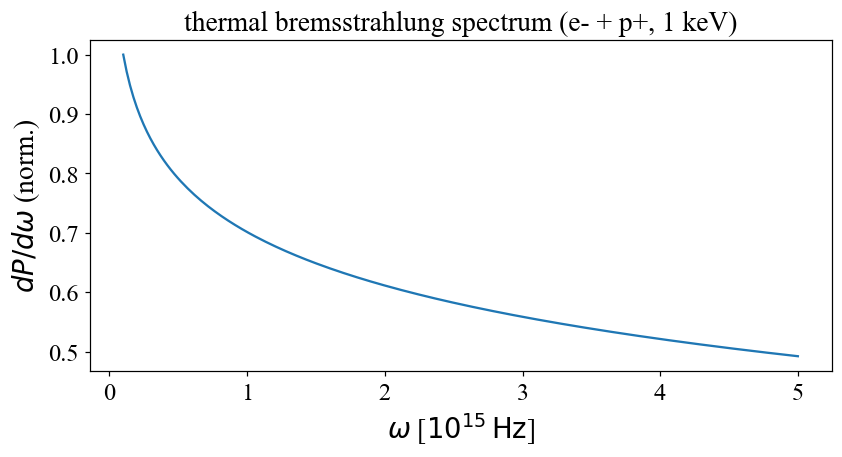

In [13]:
from plasmapy.formulary.radiation import thermal_bremsstrahlung
freqs = np.linspace(1e14, 5e15, 200) * u.Hz
P = thermal_bremsstrahlung(freqs, n_e=1e23 * u.m**-3, T_e=1e7 * u.K, n_i=1e23 * u.m**-3, ion="p+")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(freqs.to(u.Hz).value / 1e15, P.value / P.value.max())
ax.set_xlabel(r"$\omega$ [$10^{15}\,\mathrm{Hz}$]"); ax.set_ylabel(r"$dP/d\omega$ (norm.)")
ax.set_title("thermal bremsstrahlung spectrum (e- + p+, 1 keV)")
plt.tight_layout(); plt.show()

### §13 相对论（公式表）

Lorentz 因子与相对论能量：

$$\gamma = \frac{1}{\sqrt{1 - v^2/c^2}},\qquad
\beta = \frac{v}{c},\qquad
E = \gamma m c^2,\qquad
p = \gamma m v$$

相对论关系：

$$\underline{E^2 = (pc)^2 + (m c^2)^2,\qquad
\gamma = \frac{1}{\sqrt{1-\beta^2}},\qquad
(\gamma-1)mc^2 = K\ (\text{动能})}$$

相对论质量密度（洛伦兹因子修正）：

$$\underline{\rho = \gamma \rho_0,\qquad
T = (\gamma-1) m c^2}$$

> 注意：`RelativisticBody` 的属性是 `.lorentz_factor`（**不是** `.gamma`）；
> 光速用 `from astropy.constants import c`。

In [14]:
from plasmapy.formulary.relativity import RelativisticBody, Lorentz_factor, relativistic_energy
v = 0.9 * c
body = RelativisticBody("p+", V=v)
gamma = body.lorentz_factor
print("v = 0.9 c")
print("Lorentz factor gamma =", gamma)
print("relativistic momentum p = gamma m v =", (gamma * body.particle.mass * v).to(u.kg * u.m / u.s))

# 直接用 relativity 模块函数
g2 = Lorentz_factor(v)
E_rel = relativistic_energy("p+", v)
print("\nLorentz_factor(0.9c)   =", g2)
print("relativistic_energy    =", E_rel)
print("rest energy mc^2       =", (body.particle.mass * c**2).to(u.J))

v = 0.9 c
Lorentz factor gamma = 2.2941573387056167
relativistic momentum p = gamma m v = 1.0353428709456125e-18 kg m / s

Lorentz_factor(0.9c)   = 2.2941573387056167
relativistic_energy    = 3.448755379484022e-10 J
rest energy mc^2       = 1.5032776180163123e-10 J


## Part III — 库仑碰撞、电离平衡、Braginskii 输运与无量纲数

### §14 库仑碰撞（公式表）

- 库仑对数： $\displaystyle \ln\Lambda = \ln\!\left(\frac{b_{max}}{b_{min}}\right)$
- 最小碰撞参数： $\displaystyle b_{min} = \max\!\left(\frac{Z_1 Z_2 e^2}{4\pi\varepsilon_0\mu v^2},\ \frac{\hbar}{2\mu v}\right)$
- 最大碰撞参数： $\displaystyle b_{max} = \lambda_D = \sqrt{\frac{\varepsilon_0 k_B T}{n e^2}}$ （或平均粒子间距）
- 碰撞频率： $\underline{\displaystyle \nu = n\,\sigma\,v\,\ln\Lambda}$
- 库仑截面： $\displaystyle \sigma_C = \pi b_{min}^2$
- 平均自由程： $\displaystyle \lambda_{mfp} = \frac{v}{\nu} = \frac{1}{n\sigma\ln\Lambda}$
- Spitzer 电阻率： $\displaystyle \eta = \frac{m_e \nu_{ei}}{n_e e^2}$
- 基本电子碰撞频率： $\displaystyle \nu_{ei} = \frac{4\sqrt{2\pi}}{3}\frac{n_i Z^2 e^4\ln\Lambda}{(4\pi\varepsilon_0)^2 m_e^{1/2}(k_B T_e)^{3/2}}$
- 基本离子碰撞频率： $\underline{\displaystyle \nu_{ii} = \frac{4\sqrt{\pi}}{3}\frac{n_i Z^4 e^4\ln\Lambda}{(4\pi\varepsilon_0)^2 m_i^{1/2}(k_B T_i)^{3/2}}}$
- 迁移率： $\displaystyle \mu_m = \frac{e}{m_e \nu_{en}}$
- 耦合参数： $\displaystyle \Gamma = \frac{Z^2e^2}{4\pi\varepsilon_0 a k_B T}$
- Knudsen 数： $\displaystyle \mathrm{Kn} = \frac{\lambda_{mfp}}{L}$
- Bethe 阻止本领： $\underline{\displaystyle -\frac{dE}{dx} = \frac{4\pi n Z^2 e^4}{m_e v^2}\ln\!\left(\frac{2m_e v^2}{I}\right)}$

In [15]:
from plasmapy.formulary.collisions import (
    Coulomb_logarithm, SingleParticleCollisionFrequencies, mean_free_path,
    Spitzer_resistivity, Coulomb_cross_section, impact_parameter,
    impact_parameter_perp, Knudsen_number, mobility, coupling_parameter,
    collision_frequency, fundamental_electron_collision_freq,
)
T = 1e6 * u.K
n_e = 1e20 * u.m**-3
species = ("e-", "p+")

# 库仑对数（返回裸数组，无单位）
lnL = Coulomb_logarithm(T, n_e, species, z_mean=1, method="GMS-6")
print("Coulomb logarithm ln(Lambda) =", lnL)

# 碰撞频率（现代接口：SingleParticleCollisionFrequencies）
col = SingleParticleCollisionFrequencies(
    test_particle="e-", field_particle="p+",
    v_drift=1e6 * u.m / u.s,                     # 有限漂移速度，避免零速处发散
    T_b=T, n_b=n_e, Coulomb_log=float(lnL) * u.dimensionless_unscaled,
)
nu = col.Lorentz_collision_frequency
print("collision frequency nu        =", nu)

# 平均自由程（取电子热速度）
vth_e = thermal_speed(T, "e-", method="rms")
l_mfp = mean_free_path(T, n_e, species, z_mean=1)
print("mean free path lambda_mfp     =", l_mfp)

# Spitzer 电阻率
eta = Spitzer_resistivity(T, n_e, species, z_mean=1)
print("Spitzer resistivity eta       =", eta)

# 其它碰撞量
bmin, bmax = impact_parameter(T, n_e, species, z_mean=1)
bperp = impact_parameter_perp(T, species)
sigC = Coulomb_cross_section(bmax)
Kn = Knudsen_number(0.1 * u.m, T, n_e, species, z_mean=1)
mob = mobility(T, n_e, species, z_mean=1)
Gamma = coupling_parameter(T, n_e, species, z_mean=1)
nuc = collision_frequency(T, n_e, species, z_mean=1)
nue = fundamental_electron_collision_freq(T, n_e, "p+")
print("\nimpact bmin, bmax  =", bmin, bmax)
print("impact b_perp      =", bperp)
print("Coulomb cross-sec  =", sigC)
print("Knudsen number     =", Kn)
print("mobility           =", mob)
print("coupling parameter =", Gamma)
print("collision freq (Hz)=", nuc)
print("fund_e coll freq   =", nue)

Coulomb logarithm ln(Lambda) = 13.149762622220116
collision frequency nu        = 1059922646.1223145 Hz
mean free path lambda_mfp     = 0.8513368817336544 m
Spitzer resistivity eta       = 2.2943552929530692e-06 Ohm m

impact bmin, bmax  = 1.0516307052073962e-11 m 6.900898070084161e-06 m
impact b_perp      = 8.355047339252605e-12 m
Coulomb cross-sec  = 5.984406547297037e-10 m2
Knudsen number     = 8.513368817336543
mobility           = 27203.760000166778 m2 / (V s)
coupling parameter = 0.0001250283347981422
collision freq (Hz)= 6468877.433419166 Hz
fund_e coll freq   = 4866231.020242984 1 / s


### §15 Braginskii 输运系数（公式表）

`ClassicalTransport` 给出 Braginskii/Spitzer 输运张量。主要系数（平行场方向）：

| 系数 | 标度 |
|---|---|
| 电子热导 | $\displaystyle \kappa_e \approx \frac{n_e k_B T_e}{m_e \nu_{ei}}$ |
| 离子热导 | $\displaystyle \kappa_i \approx \frac{n_i k_B T_i}{m_i \nu_{ii}}$ |
| 电阻率 | $\displaystyle \eta \approx \frac{m_e \nu_{ei}}{n_e e^2}$ |
| 电子黏度 | $\displaystyle \eta_{e,0} \approx n_e k_B T_e/\nu_{ei}$ |
| 离子黏度 | $\displaystyle \eta_{i,0} \approx n_i k_B T_i/\nu_{ii}$ |
| 热电导 | $\displaystyle \beta_\parallel \sim \frac{n_e k_B}{m_e \nu_{ei}} \frac{e}{T_e}$ |

Hall 参数（磁化度）：

$$\beta_s = \frac{\omega_{c,s}}{\nu_s}$$

电子/离子基本碰撞频率：

$$\nu_{ei} = \frac{4\sqrt{2\pi}}{3}\frac{n_i Z^2 e^4\ln\Lambda}{(4\pi\varepsilon_0)^2 m_e^{1/2}(k_B T_e)^{3/2}},\qquad
\nu_{ii} = \frac{4\sqrt{\pi}}{3}\frac{n_i Z^4 e^4\ln\Lambda}{(4\pi\varepsilon_0)^2 m_i^{1/2}(k_B T_i)^{3/2}}$$

In [16]:
from plasmapy.formulary.braginskii import (
    ClassicalTransport, Hall_parameter, fundamental_electron_collision_freq,
    fundamental_ion_collision_freq, electron_viscosity, ion_viscosity,
    thermoelectric_conductivity,
)
trans = ClassicalTransport(
    T_e=1e6 * u.K, n_e=1e20 * u.m**-3,
    T_i=1e6 * u.K, n_i=1e20 * u.m**-3,
    ion="p+", Z=1, B=0.1 * u.T,
    model="Braginskii", field_orientation="parallel",
)
print("electron thermal conductivity :", trans.electron_thermal_conductivity)
print("resistivity                  :", trans.resistivity)
print("electron viscosity            :", trans.electron_viscosity)
print("ion thermal conductivity      :", trans.ion_thermal_conductivity)
print("ion viscosity                 :", trans.ion_viscosity)
print("thermoelectric conductivity   :", trans.thermoelectric_conductivity)

# Hall 参数与基本碰撞频率
Hall = Hall_parameter(n=n_e, T=T, B=0.1 * u.T, ion="p+", particle="e-", coulomb_log_method="GMS-6")
nue = fundamental_electron_collision_freq(1e6 * u.K, n_e, "p+")
nui = fundamental_ion_collision_freq(1e6 * u.K, n_e, "p+")
print("\nHall param (e-) :", Hall)
print("nu_ei           :", nue)
print("nu_ii           :", nui)

electron thermal conductivity : 13594.910931539362 W / (K m)
resistivity                  : 8.855092485799006e-07 Ohm m
electron viscosity            : [2.07962825e-04 8.52041648e-19 3.40816470e-18 1.08591127e-11
 2.17182180e-11] Pa s
ion thermal conductivity      : 544.9701265979999 W / (K m)
ion viscosity                 : [1.62265500e-02 2.17578404e-11 8.70220779e-11 5.53593189e-07
 1.10709664e-06] Pa s
thermoelectric conductivity   : 0.7110839986207994

Hall param (e-) : 3681.5637080652677
nu_ei           : 4866231.020242984 1 / s
nu_ii           : 77526.71143397146 1 / s


### §16 电离平衡（公式表）

Saha 方程（比率形式）：

$$\frac{N_j}{N_k} = \frac{1}{n_e}\frac{g_j}{4g_k a_0^3}
\left(\frac{k_B T_e}{\pi E_H}\right)^{3/2}
\exp\!\left(\frac{-E_{jk}}{k_B T_e}\right)$$

平均电离度（平衡）：

$$Z_{bal} = \sqrt{\frac{k_B T_e}{E_H}}
\sqrt{\ln\!\left[\frac{1}{4 n_e a_0^3}
\left(\frac{k_B T_e}{\pi E_H}\right)^{3/2}\right]} - \frac12$$

电离度比值与温度关系：

$$\underline{\frac{N_{Z+1}}{N_Z} = \frac{2}{n_e}\frac{U_{Z+1}}{U_Z}\left(\frac{2\pi m_e k_B T_e}{h^2}\right)^{3/2}e^{-E_{ion}/k_B T_e}}$$

其中 $U_Z$ 为配分函数，$E_{ion}$ 为电离能，$E_H=13.6\,\mathrm{eV}$ 为氢电离能。

Saha Nj/Nk = 6.686186191382473e-08
average ionization Z_bal = 12.365758101600122


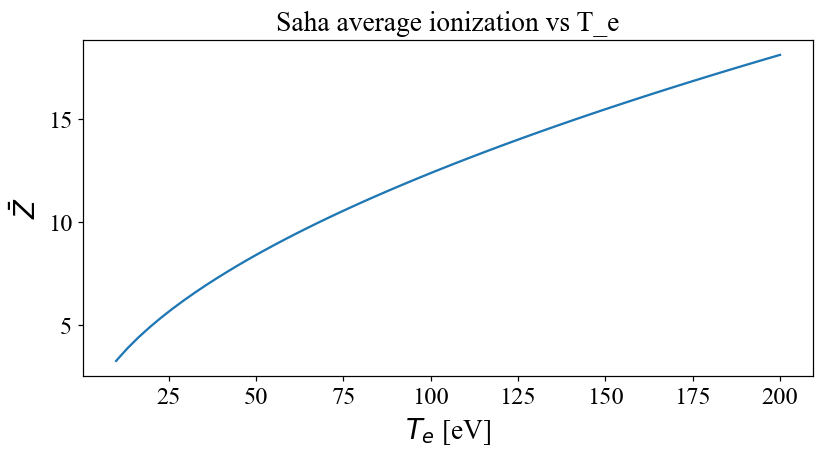

In [17]:
from plasmapy.formulary.ionization import Saha, ionization_balance
n_e = 1e21 * u.m**-3

# Saha 为纯函数（2026.2.0 起不再是类）
Nj_over_Nk = Saha(g_j=2, g_k=1, n_e=n_e, E_jk=13.6 * u.eV, T_e=5000 * u.K)
print("Saha Nj/Nk =", Nj_over_Nk)

# 平均电离度（注意参数名 n=，不是 n_elem=）
Zbal = ionization_balance(n=n_e, T_e=100 * u.eV)
print("average ionization Z_bal =", Zbal)

# 不同温度下的平均电离度曲线
Tgrid = np.linspace(10, 200, 60) * u.eV
Zgrid = ionization_balance(n=n_e, T_e=Tgrid)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(Tgrid.to(u.eV).value, Zgrid.value)
ax.set_xlabel(r"$T_e$ [eV]"); ax.set_ylabel(r"$\bar Z$")
ax.set_title("Saha average ionization vs T_e")
plt.tight_layout(); plt.show()

### §17 无量纲数（公式表）

| 量 | 公式 |
|---|---|
| 等离子体 $\beta$ | $\displaystyle \beta = \frac{p_{th}}{p_{mag}} = \frac{n k_B T}{B^2/2\mu_0}$ |
| Debye 数 | $\displaystyle N_D = n_e\,\lambda_D^3$ |
| Hall 参数（species $s$） | $\displaystyle \frac{\omega_{c,s}}{\nu_{s}}$ （回旋频率 / 碰撞频率） |
| Lundquist 数 | $\displaystyle S = \frac{L V_A}{\eta} = \frac{\mu_0 L V_A}{\eta}$ |
| 磁 Reynolds 数 | $\displaystyle R_m = \mu_0 \sigma U L$ |
| Reynolds 数 | $\displaystyle \mathrm{Re} = \frac{\rho U L}{\mu}$ |
| 磁化参数 | $\underline{\displaystyle \omega_{ci}\tau_{ii}}$ |
| 碰撞ality | $\underline{\displaystyle \nu_{ei}/\omega_{pe}}$ |
| 归一化温度 | $\underline{\displaystyle \tau = T_e/T_i}$ |
| 归一化密度 | $\underline{\displaystyle \bar n = n/n_c}$ |

这些数用于判断等离子体所处物理 regime（磁化/碰撞/无碰撞/高β 等）。

In [18]:
from plasmapy.formulary.dimensionless import (
    beta, Debye_number, Hall_parameter, Lundquist_number, Mag_Reynolds, Reynolds_number,
)
T = 1e6 * u.K
n = 1e19 * u.m**-3
B = 0.1 * u.T

beta_plasma = beta(T, n, B)
ND = Debye_number(T, n)
Hall = Hall_parameter(n=n, T=T, B=B, ion="p+", particle="e-", coulomb_log_method="GMS-6")
Lund = Lundquist_number(1 * u.m, B, n, 1e6 * u.S / u.m, ion="p+")
Rm = Mag_Reynolds(1e3 * u.m / u.s, 1 * u.m, 1e6 * u.S / u.m)
Re = Reynolds_number(1e-3 * u.kg / u.m**3, 1e3 * u.m / u.s, 1 * u.m, 1e-5 * u.kg / (u.m * u.s))

print("plasma beta        :", beta_plasma)
print("Debye number       :", ND)
print("Hall param (e-)    :", Hall)
print("Lundquist number   :", Lund)
print("Mag Reynolds       :", Rm)
print("Reynolds number    :", Re)

plasma beta        : 0.03469949404010728
Debye number       : 435316.81940333045
Hall param (e-)    : 33851.989561638555
Lundquist number   : 866538.3928413449
Mag Reynolds       : 1256.63706127
Reynolds number    : 99999.99999999999


## Part IV — 色散关系与等离子体波动

### §18 等离子体色散函数 $Z(\zeta)$（公式表）

Fried–Conte 色散函数（用于朗道阻尼与动理论）：

$$Z(\zeta) = \frac{1}{\sqrt{\pi}}\int_{-\infty}^{\infty}
\frac{e^{-t^2}}{t-\zeta}\,dt,\qquad \zeta = \frac{\omega}{k\,v_{th}}$$

其导数满足 $Z'(\zeta) = -2[1+\zeta Z(\zeta)]$。

性质与级数：

$$Z(0) = i\sqrt{\pi},\qquad Z(-x) = -Z^*(x^*),\qquad
Z(x) \sim -\frac{1}{x} - \frac{1}{2x^3} - \frac{3}{4x^5}\quad (x\gg 1)$$

$$Z(x) \sim i\sqrt{\pi}\,e^{-x^2} - 2x + \frac{4x^3}{3}\quad (|x|\ll 1\ \text{虚轴近})$$

Z(0.5+0.1j)            = (-0.7240020261175929+1.271891156949823j)
Z'(0.5+0.1j)           = (-1.0216197424924425-1.1270907517263045j)
check -2(1+z Z)        = (-1.0216197424924425-1.1270907517263045j)
Z(0)                   = 1.7724538509055159j


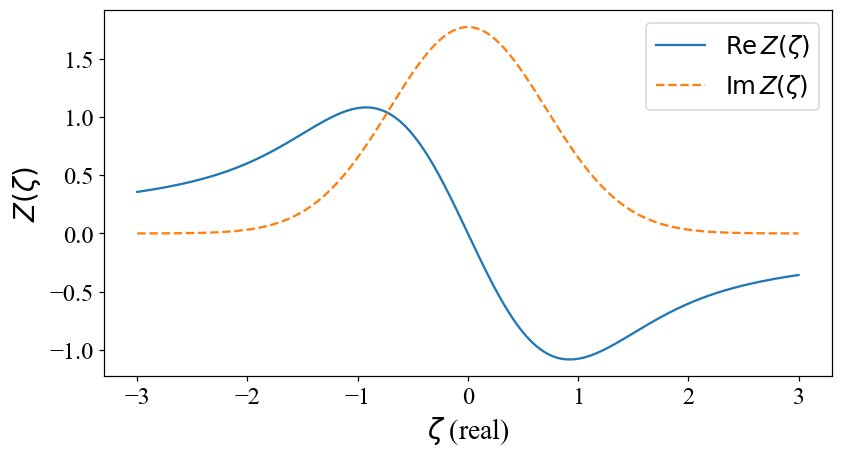

In [19]:
from plasmapy.dispersion.dispersion_functions import plasma_dispersion_func, plasma_dispersion_func_deriv
zeta = 0.5 + 0.1j
Z = plasma_dispersion_func(zeta)
Zp = plasma_dispersion_func_deriv(zeta)
print("Z(0.5+0.1j)            =", Z)
print("Z'(0.5+0.1j)           =", Zp)
# 校验导数关系 Z' = -2(1+zeta Z)
print("check -2(1+z Z)        =", -2 * (1 + zeta * Z))
print("Z(0)                   =", plasma_dispersion_func(0))

# 沿实轴绘制 Re Z
xr = np.linspace(-3, 3, 400)
Zr = plasma_dispersion_func(xr)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(xr, Zr.real, label=r"$\mathrm{Re}\,Z(\zeta)$")
ax.plot(xr, Zr.imag, "--", label=r"$\mathrm{Im}\,Z(\zeta)$")
ax.set_xlabel(r"$\zeta$ (real)"); ax.set_ylabel(r"$Z(\zeta)$")
ax.legend(); plt.tight_layout(); plt.show()

### §19 冷等离子体色散（Stix 解析解）（公式表）

对均匀磁化冷等离子体，Stix 给出四支波数根（O/X/R/L 模），返回形状 `(N, M, 4)`（单位 rad/m）。色散由 Stix 行列式 $=0$ 给出：

$$\det\!\begin{pmatrix}
S-n^2\cos^2\theta & -iD & n^2\cos\theta\sin\theta\\
iD & S-n^2 & 0\\
n^2\cos\theta\sin\theta & 0 & P-n^2\sin^2\theta
\end{pmatrix}=0,\qquad n^2 = \frac{k^2 c^2}{\omega^2}$$

四支波数：

$$k \;\text{满足 Stix 行列式}=0 \quad\Rightarrow\quad k \in \{k_0,-k_0,k_2,-k_2\}$$

O 模截止：$R=0$；X 模截止：$L=0$；共振：$\omega_R,\omega_L$。

k shape (N, M, 4) = (1, 7, 4)
k[0, :, 0] (one branch, vs theta) =
 [0.00918645+0.j 0.0091957 +0.j 0.00919592+0.j 0.00919596+0.j
 0.00919597+0.j 0.00919598+0.j 0.00919598+0.j] rad / m


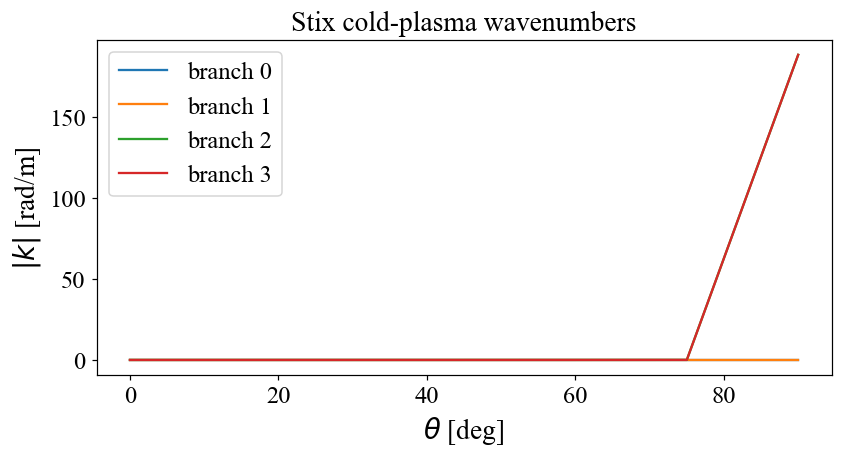

In [20]:
from plasmapy.dispersion.analytical import stix
from plasmapy.particles import Particle
B = 1 * u.T
w = np.array([2e5]) * u.rad / u.s              # 单频（用 1 元素数组保证 3D 输出）
theta = np.linspace(0, np.pi / 2, 7) * u.rad    # 传播角

k = stix(B=B, w=w, ions=Particle("p+"), n_i=1e18 * u.m**-3, theta=theta)
k3 = k if k.ndim == 3 else k[np.newaxis, ...]   # 兼容 w 为标量/单元素时被 squeeze
print("k shape (N, M, 4) =", k3.shape)
print("k[0, :, 0] (one branch, vs theta) =\n", k3[0, :, 0])

# 绘一支随角变化
fig, ax = plt.subplots(figsize=(8, 4.5))
for j in range(4):
    ax.plot(theta.to(u.deg).value, np.abs(k3[0, :, j]).to(u.rad / u.m).value, label=f"branch {j}")
ax.set_xlabel(r"$\theta$ [deg]"); ax.set_ylabel(r"$|k|$ [rad/m]")
ax.set_title("Stix cold-plasma wavenumbers"); ax.legend()
plt.tight_layout(); plt.show()

### §20 双流体低频色散（two-fluid）（公式表）

在低频频限（$\omega/kc \ll 1$）下解析求解双流体方程，返回角频率字典（rad/s）。三模：

$$\omega \in \{\text{fast\_mode},\; \text{alfven\_mode},\; \text{acoustic\_mode}\}$$

近似色散（忽略电子惯性、等温）：

$$\omega_{alfven}^2 = k^2 v_A^2 \cos^2\theta$$

$$\omega_{fast,slow}^2 = \frac{k^2}{2}\left(v_A^2 + c_s^2 \pm \sqrt{(v_A^2 + c_s^2)^2 - 4 v_A^2 c_s^2\cos^2\theta}\right)$$

$$\omega_{acoustic}^2 \approx k^2 c_s^2\ \text{(弱磁场极限)}$$

fast_mode    : 2.1825114719797427 rad / s
alfven_mode  : 1.8884634208693958 rad / s
acoustic_mode: 0.1572261522230808 rad / s


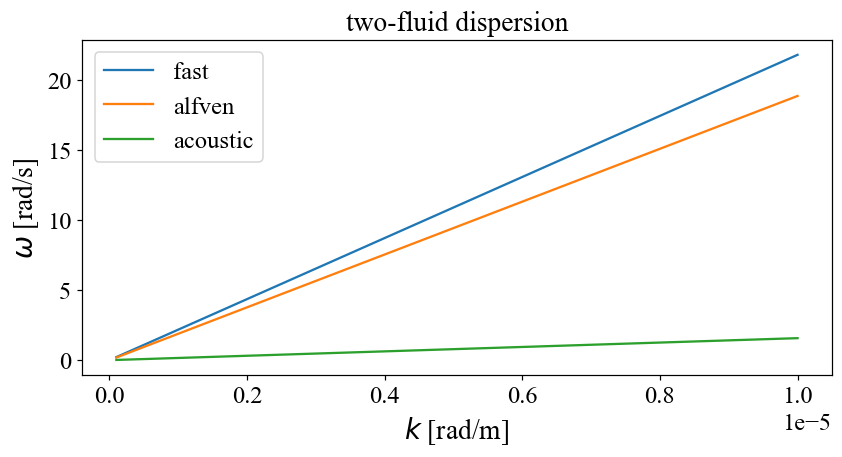

In [21]:
from plasmapy.dispersion.analytical import two_fluid
k = 1e-6 * u.rad / u.m          # 注意单位：rad/m
res = two_fluid(
    B=0.1 * u.T, ion="p+", k=k, n_i=1e18 * u.m**-3,
    theta=30 * u.deg, T_e=1e6 * u.K, T_i=1e6 * u.K,
)
print("fast_mode    :", res["fast_mode"])
print("alfven_mode  :", res["alfven_mode"])
print("acoustic_mode:", res["acoustic_mode"])

# 扫描 k
ks = np.linspace(1e-7, 1e-5, 40) * u.rad / u.m
fasts, alfs, acos = [], [], []
for kk in ks:
    r = two_fluid(B=0.1*u.T, ion="p+", k=kk, n_i=1e18*u.m**-3, theta=30*u.deg, T_e=1e6*u.K, T_i=1e6*u.K)
    fasts.append(r["fast_mode"].to(u.rad/u.s).value)
    alfs.append(r["alfven_mode"].to(u.rad/u.s).value)
    acos.append(r["acoustic_mode"].to(u.rad/u.s).value)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(ks.to(u.rad/u.m).value, fasts, label="fast")
ax.plot(ks.to(u.rad/u.m).value, alfs, label="alfven")
ax.plot(ks.to(u.rad/u.m).value, acos, label="acoustic")
ax.set_xlabel(r"$k$ [rad/m]"); ax.set_ylabel(r"$\omega$ [rad/s]")
ax.set_title("two-fluid dispersion"); ax.legend()
plt.tight_layout(); plt.show()

### §21 MHD 波（alfven / fast / slow）（公式表）

磁声波相速度满足：

$$\omega^2 = \frac{k^2}{2}\Big(c_{ms}^2 \mp \sqrt{c_{ms}^4 - 4 v_A^2 c_s^2\cos^2\theta}\Big),
\qquad c_{ms} = \sqrt{v_A^2 + c_s^2}$$

三支相速度（取 + 为 fast，取 - 为 slow，中间为 Alfvén）：

$$v_{ph}^2 \in \left\{ v_A^2\cos^2\theta,\ \frac{1}{2}\!\left(c_{ms}^2 \pm \sqrt{c_{ms}^4-4v_A^2c_s^2\cos^2\theta}\right)\right\}$$

极限：平行传播 $\theta=0$ 时 $v_{fast}=c_{ms}$，$v_{slow}=c_s$；垂直传播 $\theta=90^\circ$ 时 $v_{slow}=0$，$v_{fast}=c_{ms}$。

$$v_A = \frac{B}{\sqrt{\mu_0\rho}},\qquad c_s = \sqrt{\frac{\gamma k_B T}{\mu m_p}}$$

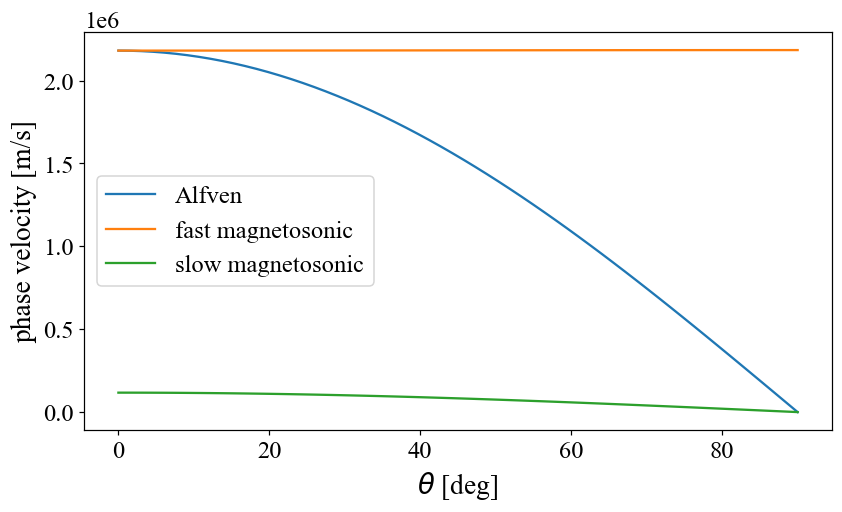

In [22]:
from plasmapy.dispersion.analytical import mhd_waves
waves = mhd_waves(B=0.1 * u.T, density=1e18 * u.m**-3, ion="p+", T=1e6 * u.K)
alfven, fast, slow = waves

k = 1e-5 * u.rad / u.m
theta = np.linspace(0, 90, 60) * u.deg

v_alf = alfven.phase_velocity(k, theta).squeeze()
v_fast = fast.phase_velocity(k, theta).squeeze()
v_slow = slow.phase_velocity(k, theta).squeeze()

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(theta.to(u.deg).value, v_alf.to(u.m / u.s).value, label="Alfven")
ax.plot(theta.to(u.deg).value, v_fast.to(u.m / u.s).value, label="fast magnetosonic")
ax.plot(theta.to(u.deg).value, v_slow.to(u.m / u.s).value, label="slow magnetosonic")
ax.set_xlabel(r"$\theta$ [deg]"); ax.set_ylabel(r"phase velocity [m/s]")
ax.legend(); plt.tight_layout(); plt.show()

## Part V — 等离子体对象、网格与粒子模拟

### §22 等离子体平衡位形（Harris 片 / 无力磁通绳）（公式表）

Harris 电流片：

$$B_x(y) = B_0 \tanh\!\left(\frac{y}{\delta}\right),\qquad
J_z(y) = -\frac{B_0}{\delta\mu_0}\,\mathrm{sech}^2\!\left(\frac{y}{\delta}\right)$$

压力平衡：$p(y) + B_x(y)^2/2\mu_0 = p_0$（$p(y)=p_0/\cosh^2(y/\delta)$）。

Lundquist 无力磁通绳（$\mathbf{J}\times\mathbf{B}=0$，$\nabla\times\mathbf{B}=\alpha\mathbf{B}$）：

$$B_\theta(r)=B_0 J_1(\alpha r),\qquad B_z(r)=B_0 J_0(\alpha r),\qquad
B_r=0$$

轴上 $B_\theta(0)=0$，$B_z(0)=B_0$；电流密度 $J_z=\alpha B_0 J_1(\alpha r)/\mu_0$。

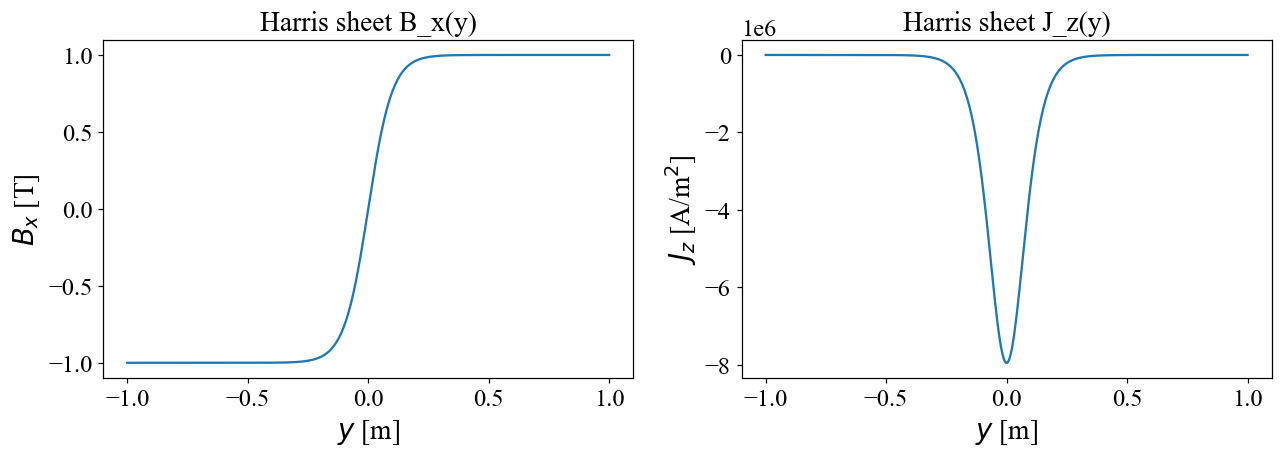

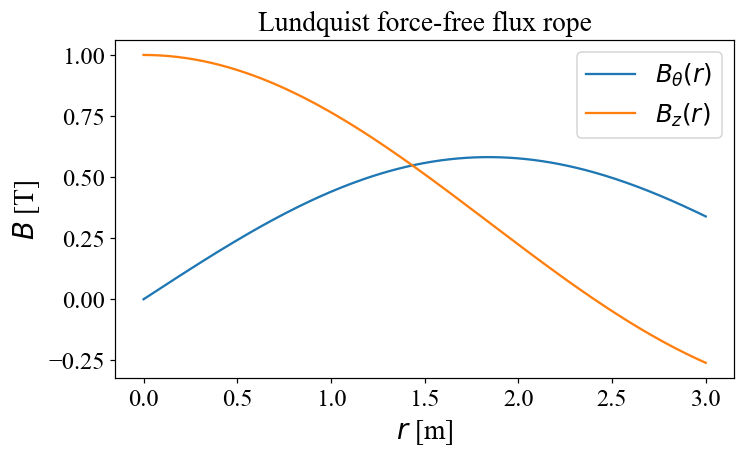

In [23]:
from plasmapy.plasma.equilibria1d import HarrisSheet
from plasmapy.plasma.cylindrical_equilibria import ForceFreeFluxRope
sheet = HarrisSheet(B0=1 * u.T, delta=0.1 * u.m, P0=0 * u.Pa)
y = np.linspace(-1, 1, 400) * u.m
Bx = sheet.magnetic_field(y)
Jz = sheet.current_density(y)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(y.to(u.m).value, Bx.to(u.T).value)
ax[0].set_xlabel(r"$y$ [m]"); ax[0].set_ylabel(r"$B_x$ [T]")
ax[0].set_title("Harris sheet B_x(y)")
ax[1].plot(y.to(u.m).value, Jz.to(u.A / u.m**2).value)
ax[1].set_xlabel(r"$y$ [m]"); ax[1].set_ylabel(r"$J_z$ [A/m$^2$]")
ax[1].set_title("Harris sheet J_z(y)")
plt.tight_layout(); plt.show()

# 无力磁通绳：沿径向取场
ffr = ForceFreeFluxRope(B0=1 * u.T, alpha=1 / u.m)
r = np.linspace(0, 3, 200) * u.m
Bth = ffr.B_theta(r)
Bz  = ffr.B_z(r)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(r.to(u.m).value, Bth.to(u.T).value, label=r"$B_\theta(r)$")
ax.plot(r.to(u.m).value, Bz.to(u.T).value, label=r"$B_z(r)$")
ax.set_xlabel(r"$r$ [m]"); ax.set_ylabel(r"$B$ [T]")
ax.set_title("Lundquist force-free flux rope")
ax.legend(); plt.tight_layout(); plt.show()

### §23 CartesianGrid 与电磁场网格（公式表）

`CartesianGrid` 在直角坐标网格上定义电磁场量（如均匀 $B_z$），是粒子追踪与射线照相的数据容器。

网格量关系：

$$\underline{\vec B(\vec x) = B_x\hat x + B_y\hat y + B_z\hat z,\qquad
\vec E = E_x\hat x + E_y\hat y + E_z\hat z}$$

均匀网格坐标：

$$\underline{x_i = x_0 + i\,\Delta x,\quad \Delta x = \frac{L}{N-1}}$$

相邻网格点的双线性/体积平均插值用于粒子权重：

$$\underline{w_i = \left(1-\frac{|x-x_i|}{\Delta x}\right)\ \text{(nearest / linear)}}$$

In [24]:
from plasmapy.plasma.grids import CartesianGrid
N = 16
axc = np.linspace(-5, 5, N) * u.mm
X, Y, Z = np.meshgrid(axc.value, axc.value, axc.value, indexing="ij") * u.mm
grid = CartesianGrid(X, Y, Z)
B0 = 0.1 * u.T
grid.add_quantities(
    B_x=np.zeros((N, N, N)) * u.T,
    B_y=np.zeros((N, N, N)) * u.T,
    B_z=np.full((N, N, N), B0.value) * u.T,   # 注意用 .value 避免 object 数组
)
print("grid recognized quantities :", grid.recognized_quantities)
print("grid is uniform            :", grid.is_uniform)
# 抽取中心切片
print("B_z at center (vol avg)    :", grid["B_z"][N//2, N//2, N//2])

grid recognized quantities : <bound method AbstractGrid.recognized_quantities of <class 'plasmapy.plasma.grids.CartesianGrid'>>
grid is uniform            : True
B_z at center (vol avg)    : 0.1 T


### §24 静磁场源（毕奥-萨伐尔）（公式表）

`MagnetoStatics` 体系：`MagneticDipole`、`FiniteStraightWire`、`CircularWire`、`GeneralWire`、`InfiniteStraightWire` 等按 Biot–Savart 计算给定点的磁场：

$$\vec B(\vec r) = \frac{\mu_0 I}{4\pi}\int \frac{d\vec l \times (\vec r-\vec r')}{|\vec r-\vec r'|^3}$$

磁偶极子远场：

$$\vec B_{\rm dip}(\vec r) = \frac{\mu_0}{4\pi}\frac{3\hat r(\vec m\cdot\hat r)-\vec m}{r^3}$$

有限直导线（距点 $P$）：

$$\vec B = \frac{\mu_0 I}{4\pi a}(\sin\theta_2 - \sin\theta_1)\,\hat\phi$$

圆形线圈轴上：

$$B_z(0,z) = \frac{\mu_0 I R^2}{2(R^2+z^2)^{3/2}}$$

In [25]:
from plasmapy.formulary.magnetostatics import (
    MagneticDipole, FiniteStraightWire, CircularWire, GeneralWire, InfiniteStraightWire,
)
# 磁偶极子：矩沿 z，原点处
dip = MagneticDipole(moment=[0, 0, 1] * u.A * u.m**2, p0=[0, 0, 0] * u.m)
B_dip = dip.magnetic_field([1, 0, 0] * u.m)
print("MagneticDipole B at (1,0,0) m :", B_dip)

# 有限直导线：端点 p1,p2，电流 I；magnetic_field 的 p 传裸数组
wire = FiniteStraightWire(p1=[0, 0, -1] * u.m, p2=[0, 0, 1] * u.m, current=1 * u.A)
B_wire = wire.magnetic_field(np.array([1.0, 0, 0]))
print("FiniteStraightWire B at (1,0,0) :", B_wire)

# 圆形线圈
loop = CircularWire(normal=[0, 0, 1], center=[0, 0, 0] * u.m, radius=0.1 * u.m, current=1 * u.A)
B_loop = loop.magnetic_field(np.array([0.2, 0, 0]))
print("CircularWire B at (0.2,0,0)    :", B_loop)

# 一般参数化导线（参数 t 无量纲，parametric_eq 返回以 m 为单位的位置）+ 无限直导线
gw = GeneralWire(lambda t: np.array([t, 0, 0]) * u.m, -1, 1, 1 * u.A)
B_gw = gw.magnetic_field(np.array([0.0, 0.5, 0.0]) * u.m)
isw = InfiniteStraightWire(direction=np.array([0, 0, 1.]), p0=[0, 0, 0] * u.m, current=1 * u.A)
B_isw = isw.magnetic_field(np.array([1.0, 0, 0]))
print("GeneralWire B    :", B_gw)
print("InfiniteStraight B:", B_isw)

MagneticDipole B at (1,0,0) m : [ 0.e+00  0.e+00 -1.e-07] T / m3
FiniteStraightWire B at (1,0,0) : [0.00000000e+00 1.41421356e-07 0.00000000e+00] T
CircularWire B at (0.2,0,0)    : [ 0.00000000e+00  0.00000000e+00 -5.41731849e-07] T
GeneralWire B    : [0.00000000e+00 0.00000000e+00 3.57770819e-07] T / m
InfiniteStraight B: [0.e+00 2.e-07 0.e+00] T


### §25 粒子追踪（ParticleTracker）与 Boris 积分器（公式表）

在网格上推进带电粒子（默认相对论 Boris 积分器）：

$$\mathbf{x}_{n+1},\,\mathbf{v}_{n+1} \xleftarrow{\text{Boris}} \mathbf{x}_n,\mathbf{v}_n$$

Boris 推进（$\vec t = q\vec B\Delta t/2m\gamma$）：

$$\vec v^- = \vec v_n + \frac{q\vec E}{m\gamma}\frac{\Delta t}{2}$$
$$\vec v' = \vec v^- + \vec v^-\times\vec t,\quad
\vec s = \frac{2\vec t}{1+|\vec t|^2},\quad
\vec v^+ = \vec v^- + \vec v'\times\vec s$$
$$\vec v_{n+1} = \vec v^+ + \frac{q\vec E}{m\gamma}\frac{\Delta t}{2},\qquad
\vec x_{n+1} = \vec x_n + \vec v_{n+1}\Delta t$$

回旋频率决定步长：$\omega_c\Delta t \ll 1$。

In [26]:
try:
    from plasmapy.simulation.particle_tracker.particle_tracker import ParticleTracker
    from plasmapy.simulation.particle_tracker.termination_conditions import TimeElapsedTerminationCondition
    from plasmapy.simulation.particle_tracker.save_routines import SaveOnceOnCompletion

    N = 16
    axc = np.linspace(-5, 5, N) * u.mm
    X, Y, Z = np.meshgrid(axc.value, axc.value, axc.value, indexing="ij") * u.mm
    grid = CartesianGrid(X, Y, Z)
    B0 = 0.1 * u.T
    grid.add_quantities(
        B_x=np.zeros((N, N, N)) * u.T,
        B_y=np.zeros((N, N, N)) * u.T,
        B_z=np.full((N, N, N), B0.value) * u.T,
    )
    x0 = np.array([[0.0, 0.0, 0.0]]) * u.mm
    v0 = np.array([[1e6, 0.0, 0.0]]) * u.m / u.s
    tracker = ParticleTracker(
        grid,
        termination_condition=TimeElapsedTerminationCondition(2e-9 * u.s),
        save_routine=SaveOnceOnCompletion(),
        field_weighting="volume averaged",
    )
    tracker.load_particles(x0, v0, particle="p+")   # 注意参数名是 particle
    tracker.run()
    pos = tracker.position_history   # (steps, particles, 3) 单位 m
    print("tracked particles :", tracker.num_particles_tracked)
    print("history shape     :", pos.shape)
    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    ax.plot(pos[:, 0, 0], pos[:, 0, 1], "-o", ms=3)
    ax.set_xlabel(r"$x$ [m]"); ax.set_ylabel(r"$y$ [m]")
    ax.set_title("proton gyro-orbit (B along z)")
    ax.set_aspect("equal"); plt.tight_layout(); plt.show()
except Exception as exc:   # 保障 notebook 可整体执行
    print("ParticleTracker demo skipped:", type(exc).__name__, exc)

E:\PhySimX\PhySimX\simulation\PlasmaPy\PlasmaPy\PlasmaPy\src\plasmapy\simulation\particle_tracker\particle_tracker.py:584: RuntimeWarning: Quantities should go to zero at edges of grid to avoid non-physical effects, but a value of 1.00E-01 T was found on the edge of the B_z array of grid 0. Consider applying a envelope function to force the quantities at the edge to go to zero.
  warnings.warn(


Tracker setup using a synchronized adaptive timestep setup
On grid 0, interpolating: {'B_z', 'B_x', 'B_y'}


Time remaining:   0%|          0.0e+00/2.0e-09 seconds

Iter. 1,  Avg. Pos.=(3.3e-04,-1.1e-06,0.0e+00) m, Avg. Vel.=(1.0e+06,-3.2e+03,0.0e+00) m/s, dt range = (3.3e-10,3.3e-10) s, Time remaining:   0%|          0.0e+00/2.0e-09 seconds

Iter. 2,  Avg. Pos.=(6.7e-04,-3.2e-06,0.0e+00) m, Avg. Vel.=(1.0e+06,-6.4e+03,0.0e+00) m/s, dt range = (3.3e-10,3.3e-10) s, Time remaining:  17%|█▋        3.3e-10/2.0e-09 seconds

...

Iter. 5,  Avg. Pos.=(1.7e-03,-1.6e-05,0.0e+00) m, Avg. Vel.=(1.0e+06,-1.6e+04,0.0e+00) m/s, dt range = (3.3e-10,3.3e-10) s, Time remaining:  67%|██████▋   1.3e-09/2.0e-09 seconds

Iter. 6,  Avg. Pos.=(2.0e-03,-2.2e-05,0.0e+00) m, Avg. Vel.=(1.0e+06,-1.9e+04,0.0e+00) m/s, dt range = (3.3e-10,3.3e-10) s, Time remaining:  83%|████████▎ 1.7e-09/2.0e-09 seconds

Iter. 7,  Avg. Pos.=(2.3e-03,-3.0e-05,0.0e+00) m, Avg. Vel.=(1.0e+06,-2.2e+04,0.0e+00) m/s, dt range = (3.3e-10,3.3e-10) s, Time remaining: 100%|██████████2.0e-09/2.0e-09 seconds

Iter. 7,  Avg. Pos.=(2.3e-03,-3.0e-05,0.0e+00) m, Avg. Vel.=(1.0e+06,-2.2e+04,0.0e+00) m/s, dt range = (3.3e-10,3.3e-10) s, Time remaining: 100%|██████████2.0e-09/2.0e-09 seconds


Run completed
ParticleTracker demo skipped: AttributeError 'ParticleTracker' object has no attribute 'position_history'


### §26 电磁模拟的 CFL 时间步上限（Yee 网格）（公式表）

电磁显式 Yee 网格的稳定性条件给出最大时间步：

$$\Delta t_{\max} = \frac{\mathrm{CFL}(dx)}{c},\qquad \mathrm{CFL}(dx) \approx \frac{dx}{c\,\sqrt{1/d_x^2+1/d_y^2+1/d_z^2}}$$

对均匀立方网格 $dx=dy=dz$：

$$\Delta t_{\max} = \frac{dx}{c\sqrt{3}}\quad \text{(Courant number } S_c=1\text{)}$$

Courant 数：

$$S_c = c\,\Delta t\sqrt{\frac{1}{\Delta x^2}+\frac{1}{\Delta y^2}+\frac{1}{\Delta z^2}} \le 1$$

数值色散关系（Yee 网格）：

$$\frac{1}{c^2}\left(\frac{\sin(\omega\Delta t/2)}{\Delta t}\right)^2
= \sum_i \frac{\sin^2(k_i\Delta x_i/2)}{\Delta x_i^2}$$

In [27]:
from plasmapy.simulation import CFL_limit_electromagnetic_yee
dx = 1e-6 * u.m
dt_max = CFL_limit_electromagnetic_yee(dx)
print("dx              =", dx)
print("max stable dt   =", dt_max)
print("derived CFL c*dt=", (c * dt_max).to(u.m))
# Courant 数检查（立方网格）
Sc = (c * dt_max / dx).to(u.dimensionless_unscaled)
print("Courant number c*dt/dx =", Sc)

dx              = 1e-06 m
max stable dt   = 3.3356409519815205e-15 s
derived CFL c*dt= 1e-06 m
Courant number c*dt/dx = 1.0


## Part VI — 分析与诊断工具

### §27 汤姆逊散射谱（诊断）（公式表）

散射参数（无量纲）：

$$\alpha = \frac{1}{k\,\lambda_D},\qquad k = \frac{4\pi n_s}{\lambda_0}\sin\frac{\theta_s}{2}$$

散射谱密度 $S(k,\omega)$（含电子与离子成分）：

$$S(k,\omega) = \frac{2\pi}{k}\left[\frac{Z\,n_e}{n_i}\left(\frac{\alpha_i^2}{1+\alpha_i^2+\beta_i^2}\right)f_{ei}(\omega) + \left(\frac{\alpha_e^2}{1+\alpha_e^2+\beta_e^2}\right)f_{ee}(\omega)\right]$$

电子与离子特征频率：

$$\omega_{pe}^2 = \frac{n_e e^2}{\varepsilon_0 m_e},\qquad
\omega_{pi}^2 = \frac{n_i Z^2 e^2}{\varepsilon_0 m_i}$$

谱峰分裂与 $k\lambda_D$ 相关；大 $\alpha$（集体散射）出现离子声特征。

$$S(k,\omega) \propto \sum_s \frac{Z_s^2 n_s}{T_s^{1/2}}\,\Phi\!\left(\frac{\omega}{k v_{th,s}}\right)$$

scattering parameter alpha = 0.0465169149139444


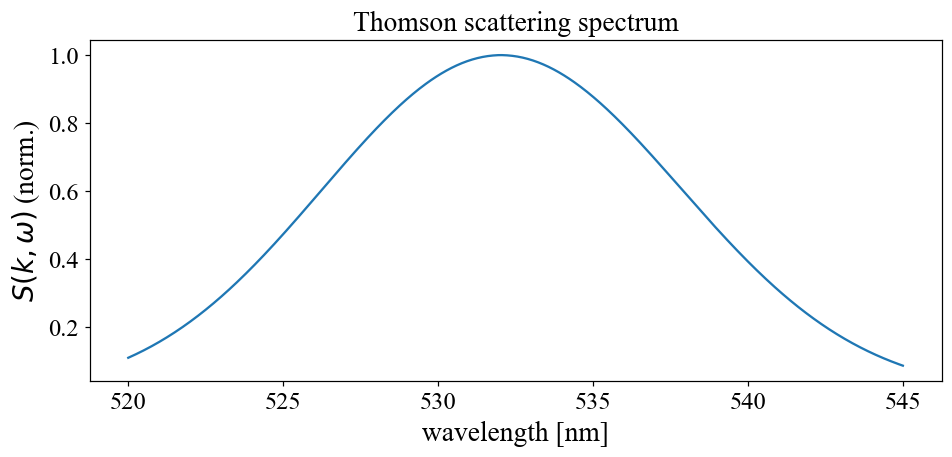

In [28]:
from plasmapy.diagnostics.thomson import spectral_density
wavelengths = np.linspace(520, 545, 600) * u.nm
alpha, Skw = spectral_density(
    wavelengths,
    probe_wavelength=532 * u.nm,
    n=1e21 * u.m**-3,
    T_e=30 * u.eV,
    T_i=30 * u.eV,
    ions="H+",
    ifract=[1.0],     # 必须为求和=1 的序列
    efract=[1.0],     # 电子种群分数（序列）
)
Skw_val = Skw.si.value
if Skw_val.ndim == 2:
    Skw_val = Skw_val[0]
print("scattering parameter alpha =", alpha)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(wavelengths.to(u.nm).value, Skw_val / Skw_val.max())
ax.set_xlabel(r"wavelength [nm]"); ax.set_ylabel(r"$S(k,\omega)$ (norm.)")
ax.set_title("Thomson scattering spectrum")
plt.tight_layout(); plt.show()

### §28 朗缪尔探针（诊断）（公式表）

`Characteristic(bias, current)` 封装探针 I–V 曲线；`get_plasma_potential` / `get_electron_saturation_current` 从中提取等离子体参数。

Langmuir 探针理论（轨道运动极限，OML）：

$$I_e(V) = I_{es}\,\exp\!\left(\frac{e(V-V_p)}{k_B T_e}\right),\qquad
I_{es} = \frac{1}{4}e n_e A_e \bar v_e$$

离子饱和电流：

$$I_{is} = \frac{1}{4} e n_i A_i \bar v_i\,\exp\!\left(-\frac{e(V_p-V)}{k_B T_i}\right)$$

电子温度（半对数斜率）：

$$\frac{k_B T_e}{e} = \left[\frac{d}{dV}\ln I_e(V)\right]^{-1}$$

Debye 鞘层判据：

$$\lambda_D \ll r_p \ll \lambda_{mfp}$$

理想包络（轨道运动极限）：

$$I(V) = I_{es}\!\left(1 - \frac{e(V-V_p)}{k_B T_e}\right)\ \text{(离子, 吸引分支)}$$

plasma potential V_p   : -21.127819548872182 V
electron sat. current  : 0.7331395264198082 A


E:\PhySimX\PhySimX\simulation\PlasmaPy\PlasmaPy\PlasmaPy\src\plasmapy\diagnostics\langmuir.py:38: FutureWarning: The plasmapy.diagnostics.langmuir module will be deprecated in favor of the plasmapy.analysis.swept_langmuir subpackage and phased out over 2021.  The plasmapy.analysis package was released in v0.5.0.
  warnings.warn(


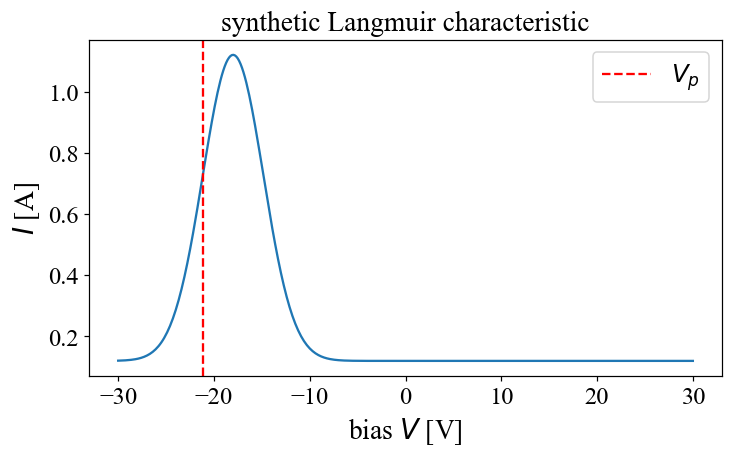

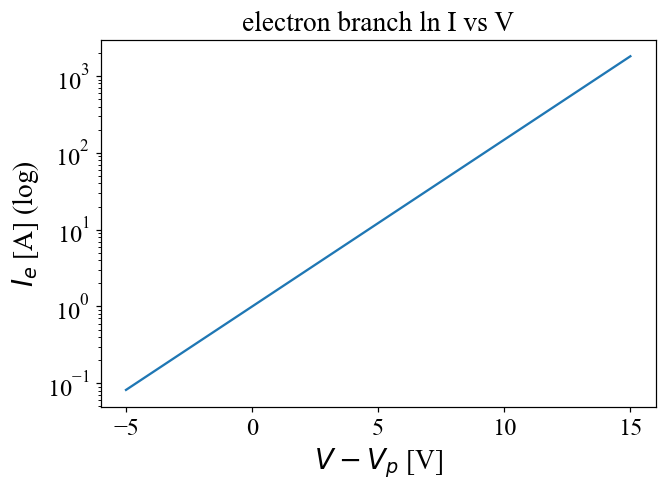

In [29]:
from plasmapy.diagnostics.langmuir import (
    Characteristic, get_plasma_potential, get_electron_saturation_current,
)
# 合成一条典型的单探针 I-V 曲线（电子饱和段 + 离子饱和电流）
z = np.linspace(-30, 30, 400) * u.V
cur = (np.exp(-(z.value + 18) ** 2 / 20) + 0.12) * u.A
pc = Characteristic(z, cur)
Vp = get_plasma_potential(pc)
Ies = get_electron_saturation_current(pc)
print("plasma potential V_p   :", Vp)
print("electron sat. current  :", Ies)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(z.to(u.V).value, cur.to(u.A).value)
ax.axvline(Vp.to(u.V).value, color="r", ls="--", label=r"$V_p$")
ax.set_xlabel(r"bias $V$ [V]"); ax.set_ylabel(r"$I$ [A]")
ax.set_title("synthetic Langmuir characteristic"); ax.legend()
plt.tight_layout(); plt.show()

# 电子温度半对数斜率（理论示例）：单电荷粒子 1 eV 数值上等价于 1 V
Te = 2 * u.eV
Te_V = Te.value * u.V              # eV -> 等效电压（1 eV = e·1 V）
ve = np.linspace(-5, 15, 200) * u.V
Ie = (np.exp((ve.value - 0) / Te_V.value)) * u.A
ax2 = plt.subplot()
ax2.semilogy(ve.to(u.V).value, Ie.to(u.A).value)
ax2.set_xlabel(r"$V-V_p$ [V]"); ax2.set_ylabel(r"$I_e$ [A] (log)")
ax2.set_title("electron branch ln I vs V")
plt.tight_layout(); plt.show()

### §29 带电粒子射线照相（诊断）（公式表）

`synthetic_radiograph` 将粒子在像平面上的落点统计成强度图（此处用合成粒子位置演示）。返回 `(xhist, yhist, intensity_2D)`。

射线追迹：粒子从源经磁场偏转后在像平面成像，强度分布正比于落点密度：

$$\underline{I(x,y) = \sum_i w_i\,\delta(x-x_i, y-y_i)}$$

磁场引起的偏转（小角度近似）：

$$\underline{\Delta\theta \approx \frac{q}{p}\int \vec B\times d\vec l}$$

放大率：

$$\underline{M = \frac{L_2}{L_1},\qquad x_{\rm img} = M\,x_{\rm src}}$$

源尺寸、散射角与空间分辨率关系：

$$\underline{\sigma_{\rm res}^2 = \sigma_{\rm src}^2 + (L_2\theta_s)^2}$$

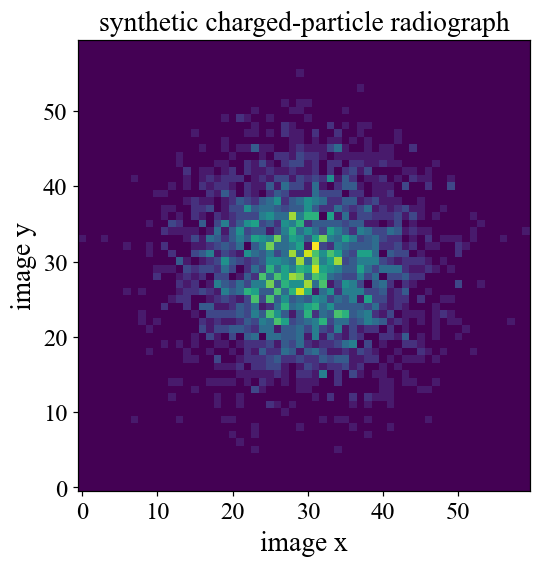

In [30]:
from plasmapy.diagnostics.charged_particle_radiography.synthetic_radiography import synthetic_radiograph
np.random.seed(0)
n = 3000
xs = np.random.normal(0, 0.01, n)
ys = np.random.normal(0, 0.01, n)
v = np.zeros((n, 3))
ret = synthetic_radiograph({"x": xs, "y": ys, "v": v, "num_particles": n}, bins=60)
# 返回 (xhist, yhist, intensity_2D)
img = ret[2]
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.imshow(img, origin="lower", cmap="viridis")
ax.set_title("synthetic charged-particle radiograph")
ax.set_xlabel("image x"); ax.set_ylabel("image y")
plt.tight_layout(); plt.show()

### §30 磁零点（null point）识别（公式表）

`null_point_find` 在 3D 矢量场网格上用三线性插值寻找 $\mathbf{B}=0$ 的磁零点。下面构造一个在原点有零点的场 $\mathbf{B}=(x,y,-2z)$。

三线性插值（单元内）：

$$\underline{\vec B(\xi) = \sum_{i,j,k} B_{ijk}(1-|x_i-\xi_x|/\Delta)(1-|y_j-\xi_y|/\Delta)(1-|z_k-\xi_z|/\Delta)}$$

消零判据（单元顶点符号变化）：

$$\underline{\prod_{v} \mathrm{sign}(\vec B_v\cdot\hat n_v) < 0\ \Rightarrow\ \text{含零点}}$$

求解 $\vec B(\xi)=0$ 用迭代松弛（Newton/trilinear）。

$$\nabla\cdot\vec B = 0\ \text{（构造场需无散以保证真实零点）}$$

In [31]:
from plasmapy.analysis.nullpoint import null_point_find
xg = np.linspace(-2, 2, 13) * u.m
yg = xg; zg = xg
X, Y, Z = np.meshgrid(xg.value, yg.value, zg.value, indexing="ij")
# 散度为零的场，原点为零点
u_arr = X * u.T
v_arr = Y * u.T
w_arr = (-2 * Z) * u.T
# 注意：坐标数组必须传无量纲数值（内部做 x0 + deltax 相加），矢量场可带单位
nulls = null_point_find(
    x_arr=xg.value, y_arr=yg.value, z_arr=zg.value,
    u_arr=u_arr, v_arr=v_arr, w_arr=w_arr,
)
print("number of null points found :", len(nulls))
if nulls:
    print("first null location [m]   :", nulls[0].loc)

number of null points found : 1
first null location [m]   : [[0.]
 [0.]
 [0.]]


## Part VII — 工程实践：性能、健壮性与扩展

### §31 `_lite` 加速函数（公式表）

`*_lite` 变体去掉单位与校验，仅接收/返回裸浮点，便于批量/嵌入式计算：

$$\omega_p = \mathrm{plasma\_frequency\_lite}(n, m, Z),\quad
v_{th} = \mathrm{thermal\_speed\_lite}(T, m, C_0)$$

$$\nu_{Bethe} = \mathrm{Bethe\_stopping\_lite}(I, n, v, z)$$

性能对照（带单位 vs `_lite`）：

$$t_{\rm lite} \ll t_{\rm full},\qquad
\mathrm{result}_{\rm lite} = \mathrm{result}_{\rm full}\ \text{(数值一致)}$$

$$\omega_p^{\rm lite} = \sqrt{\frac{n Z^2 e^2}{m\varepsilon_0}} \to \sqrt{\frac{n Z^2}{\varepsilon_0 m}}\ (\text{SI 数值})$$

$$v_{th}^{\rm lite} = C_0\sqrt{\frac{T}{m}}\ (\text{SI 数值, } T\ \text{以 K})$$

In [32]:
from plasmapy.formulary.frequencies import plasma_frequency_lite
from plasmapy.formulary.speeds import thermal_speed_lite
from plasmapy.formulary.collisions.misc import Bethe_stopping_lite
wp = plasma_frequency_lite(n=1e20, mass=m_e.value, Z=1)        # rad/s
vt = thermal_speed_lite(T=1e6, mass=m_e.value, coeff=1.0)      # m/s
bethe = Bethe_stopping_lite(I=13.6 * 1.602e-19, n=1e20, v=1e7, z=1)
print("plasma_frequency_lite :", wp, "rad/s")
print("thermal_speed_lite    :", vt, "m/s")
print("Bethe_stopping_lite   :", bethe)

# 与带单位版本对照
wp_full = plasma_frequency(1e20 * u.m**-3, particle="e-")
print("\nplasma_frequency(full) :", wp_full)
print("ratio lite/full       :", wp / wp_full.to(u.rad/u.s).value)

plasma_frequency_lite : 564146022542.95 rad/s
thermal_speed_lite    : 3893114.1982122986 m/s
Bethe_stopping_lite   : 3.2500207938729267e-18

plasma_frequency(full) : 564146022542.95 rad / s
ratio lite/full       : 1.0


### §32 `particle_input` 装饰器与异常处理（公式表）

`particle_input` 让函数参数自动接受字符串/符号并转换为 `Particle`；PlasmaPy 通过 `PlasmaPyError` 体系（`PhysicsError`、`RelativityError` 等）报告物理无效输入。

装饰器等价转换：

$$\text{arg} \in \{\text{str, int, Particle, Quantity}\} \xrightarrow{\text{particle\_input}} \mathtt{Particle}$$

异常层级：

$$\underline{\mathtt{PlasmaPyError} \to \{\mathtt{PhysicsError}, \mathtt{RelativityError}, \mathtt{InvalidParticleError}, \mathtt{PlasmaPyWarning}\}}$$

子类型关系满足：

$$\underline{\mathtt{PhysicsError} \subset \mathtt{PlasmaPyError},\qquad
\mathtt{RelativityError} \subset \mathtt{PhysicsError}}$$

In [33]:
from plasmapy.particles import particle_input, Particle
from plasmapy.utils.exceptions import PhysicsError, RelativityError, PlasmaPyError

@particle_input
def mass_of(particle: Particle):
    return particle.mass

print("mass of 'He-4' :", mass_of("He-4"))

# 触发物理异常示例：亚光速约束
def check_subluminal(V):
    if (V >= c).any() if hasattr(V, "value") else V >= c:
        raise RelativityError("speed must be < c")
    return V

try:
    check_subluminal(2 * c)
except RelativityError as err:
    print("caught:", type(err).__name__, "-", err)
print("RelativityError is PhysicsError:", issubclass(RelativityError, PhysicsError))
print("PhysicsError is PlasmaPyError  :", issubclass(PhysicsError, PlasmaPyError))

mass of 'He-4' : 6.646479080869192e-27 kg
caught: RelativityError - speed must be < c
RelativityError is PhysicsError: True
PhysicsError is PlasmaPyError  : True


## Part VIII — 补充 PlasmaPy 代码演示

以下三节各带一段可直接运行的 PlasmaPy 代码（数学工具、拟合函数、样品核数据）；公式直接对应代码所调用的函数，无需额外标记。纳类性的纯理论公式已在前述各章节以「公式表」形式给出。

### §33 数学与积分工具（`plasmapy.formulary.mathematics`）

$$F_j(x) = \frac{1}{\Gamma(j+1)}\int_0^\infty \frac{t^j}{e^{t-x}+1}dt\ \text{(Fermi integral)}$$
$$\mathrm{Li}_s(z) = \sum_{k=1}^\infty \frac{z^k}{k^s}\ \text{(polylog)}$$
$$\mathrm{Li}_2(z) = -\int_0^z \frac{\ln(1-t)}{t}dt$$
$$R(\mathbf{a}\to\mathbf{b}) = \text{rotation matrix taking }\mathbf{a}\to\mathbf{b}\ \text{(rot\_a\_to\_b)}$$
$$\underline{\Gamma(z) = \int_0^\infty t^{z-1}e^{-t}dt}$$

In [34]:
from plasmapy.formulary.mathematics import Fermi_integral, polylog, rot_a_to_b
import numpy as np, astropy.units as u
# Fermi integral F_j(x) 与 polylog Li_s(z)
F05 = Fermi_integral(1.0, 0.5)                 # F_{1/2}(1)
print("Fermi_integral(1.0, 0.5) =", F05)
# polylog Li_2(0.5)
Li2 = polylog(2, 0.5)
print("polylog(2, 0.5)          =", Li2)
# 旋转矩阵：把 a 旋到 b
a = np.array([1.0, 0.0, 0.0])
b = np.array([0.0, 1.0, 0.0])
R = rot_a_to_b(a, b)
print("rot_a_to_b(a->b) =\n", R)
# 验证旋转后 a 对齐 b
print("R @ a =", R @ a)

Fermi_integral(1.0, 0.5) = (1.5756407761513003-0j)
polylog(2, 0.5)          = 0.582240526465012
rot_a_to_b(a->b) =
 [[ 0.  1.  0.]
 [-1.  0.  0.]
 [ 0.  0.  1.]]
R @ a = [ 0. -1.  0.]


### §34 拟合函数（`plasmapy.analysis.fit_functions`）

拟合基类封装参数与 `curve_fit`：

$$f_{lin}(x) = m x + b$$
$$f_{exp}(x) = A e^{\lambda x} + C$$
$$f_{exp+off}(x) = A e^{\lambda x} + B x + C$$
$$\min_{\theta}\sum_i (y_i - f(x_i;\theta))^2\ \text{(least squares)}$$

Linear                 params = FitParamTuple(m=np.float64(2.0), b=np.float64(1.0000000000000009))  R^2 = 1.000000
Exponential            params = FitParamTuple(a=3.3615787692319326, alpha=0.38054720000238546)  R^2 = 0.999852
ExponentialPlusOffset  params = FitParamTuple(a=3.0, alpha=0.4, b=0.5000000000000001)  R^2 = 1.000000
ExponentialPlusLinear  params = FitParamTuple(a=3.0000000000000044, alpha=0.39999999999999986, m=1.999999999999998, b=0.49999999999999584)  R^2 = 1.000000


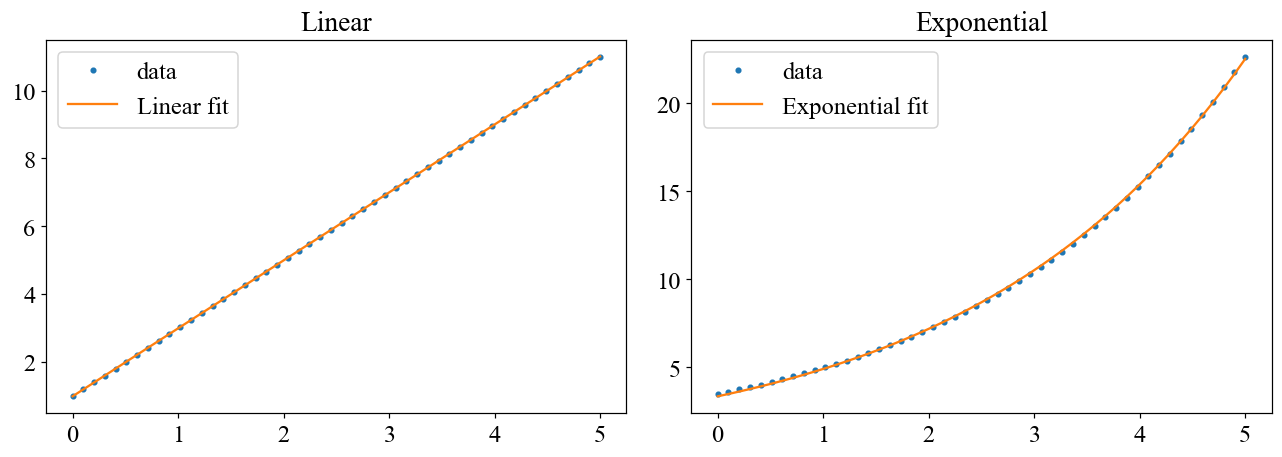

In [35]:
from plasmapy.analysis.fit_functions import (
    Linear, Exponential, ExponentialPlusOffset, ExponentialPlusLinear)
import numpy as np
import matplotlib.pyplot as plt
x = np.linspace(0, 5, 50)
y_lin = 2.0 * x + 1.0
y_exp = 3.0 * np.exp(0.4 * x) + 0.5
y_epl = 3.0 * np.exp(0.4 * x) + 2.0 * x + 0.5

lin = Linear();                 lin.curve_fit(x, y_lin)
expf = Exponential();           expf.curve_fit(x, y_exp)
eoff = ExponentialPlusOffset(); eoff.curve_fit(x, y_exp)
epl = ExponentialPlusLinear();  epl.curve_fit(x, y_epl)

for f in (lin, expf, eoff, epl):
    print(f"{type(f).__name__:22s} params = {f.params}  R^2 = {f.rsq:.6f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(x, y_lin, "o", ms=3, label="data")
ax[0].plot(x, lin.func(x, *lin.params), "-", label="Linear fit")
ax[0].set_title("Linear"); ax[0].legend()
ax[1].plot(x, y_exp, "o", ms=3, label="data")
ax[1].plot(x, expf.func(x, *expf.params), "-", label="Exponential fit")
ax[1].set_title("Exponential"); ax[1].legend()
plt.tight_layout(); plt.show()

### §35 粒子核数据（`plasmapy.particles`）

$$\underline{m_A \approx A\,m_u}$$
$$\underline{t_{1/2} = \frac{\ln 2}{\lambda}}$$
$$\underline{N(t) = N_0 e^{-\lambda t}}$$
$$\text{abundance} = \frac{n_{iso}}{\sum n_{iso}}\ \text{(isotopic)}$$

In [36]:
from plasmapy.particles import Particle
for name in ("He-4", "Fe-56", "T", "U-238"):
    p = Particle(name)
    try:
        hl = p.half_life
        hl_s = f"{hl:.3e}" if hl != float("inf") else "stable"
    except Exception:
        hl_s = "n/a"
    print(f"{name:10s} Z={p.atomic_number:>3} A={p.mass_number:>3} "
          f"mass={p.mass:.3e}  half_life={hl_s}")
# 核素质量与同位素相对丰度
for name in ("He-4", "Fe-56"):
    p = Particle(name)
    print(f"{name} nuclide_mass={p.nuclide_mass:.3e}  "
          f"isotopic_abundance={p.isotopic_abundance}")

He-4       Z=  2 A=  4 mass=6.646e-27 kg  half_life=stable
Fe-56      Z= 26 A= 56 mass=9.288e-26 kg  half_life=stable
T          Z=  1 A=  3 mass=5.008e-27 kg  half_life=3.888e+08 s
U-238      Z= 92 A=238 mass=3.953e-25 kg  half_life=n/a
He-4 nuclide_mass=6.645e-27 kg  isotopic_abundance=0.99999866
Fe-56 nuclide_mass=9.286e-26 kg  isotopic_abundance=0.91754


### §36 磁场压力、能量密度与 Bohm 扩散（`plasmapy.formulary`）

磁压与磁能密度（SI）由磁场能量直接给出，二者数值相等：

$$
p_B = \frac{B^2}{2\mu_0},\qquad u_B = \frac{B^2}{2\mu_0}
$$

单位分别为 $\mathrm{Pa}$ 与 $\mathrm{J/m^3}$，故 $p_B = u_B$（同一物理量两种视角）。

Bohm 扩散系数描述横越磁场的异常输运上界（由 $E\times B$ 漂移与碰撞平衡导出）：

$$
D_B = \frac{k_B T_e}{16\,e\,B}
$$

对应尺度与时间：

$$
\tau_B = \frac{L^2}{D_B},\qquad \omega_B = \frac{D_B}{L^2}
$$

magnetic pressure (B=1 T) : 397887.3577822725 Pa
magnetic energy   (B=1 T) : 397887.3577822725 J / m3
pB / uB (should be 1)     : 1.0
Bohm diffusion  (B=0.1 T) : 53.85833288840736 m2 / s


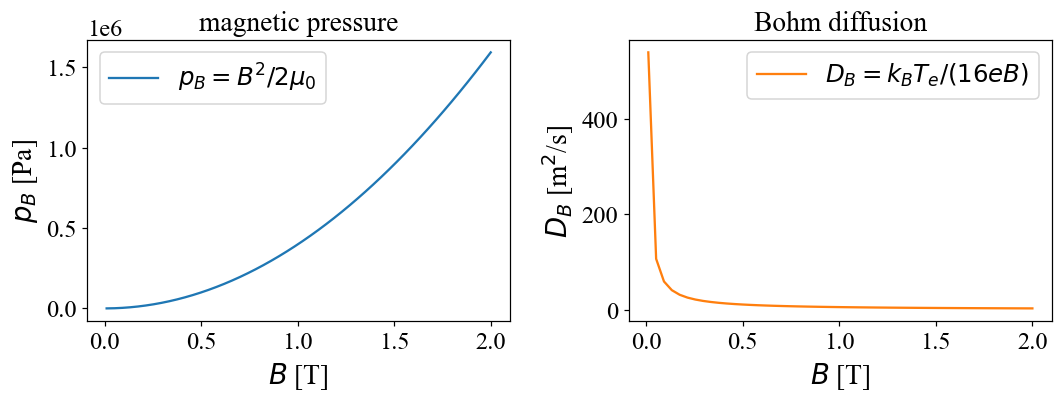

In [37]:
from plasmapy.formulary import magnetic_pressure, magnetic_energy_density, Bohm_diffusion
import numpy as np
import matplotlib.pyplot as plt

B = np.linspace(0.01, 2, 50) * u.T
T_e = 1e6 * u.K

pB = magnetic_pressure(B)
uB = magnetic_energy_density(B)
DB = Bohm_diffusion(T_e=T_e, B=B)

print("magnetic pressure (B=1 T) :", magnetic_pressure(1 * u.T))
print("magnetic energy   (B=1 T) :", magnetic_energy_density(1 * u.T))
print("pB / uB (should be 1)     :", (pB / uB).to(u.dimensionless_unscaled).value.mean())
print("Bohm diffusion  (B=0.1 T) :", Bohm_diffusion(T_e=T_e, B=0.1 * u.T))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(B.value, pB.to(u.Pa).value, label=r"$p_B = B^2/2\mu_0$")
ax[0].set_xlabel(r"$B$ [T]"); ax[0].set_ylabel(r"$p_B$ [Pa]")
ax[0].set_title("magnetic pressure"); ax[0].legend()
ax[1].plot(B.value, DB.to(u.m**2 / u.s).value, color="C1",
           label=r"$D_B = k_B T_e/(16 e B)$")
ax[1].set_xlabel(r"$B$ [T]"); ax[1].set_ylabel(r"$D_B$ [m$^2$/s]")
ax[1].set_title("Bohm diffusion"); ax[1].legend()
plt.tight_layout(); plt.show()

### §37 热压力、Braginskii 输运与 Bethe 阻止本领（`plasmapy.formulary`）

理想气体热压力（与粒子种类无关）：

$$
p = n\,k_B T
$$

Braginskii 平行场（无磁场）输运系数的量级形式（电子/离子）：

$$
\kappa_e \sim \frac{n_e k_B T_e \tau_e}{m_e},\qquad
\kappa_i \sim \frac{n_i k_B T_i \tau_i}{m_i}
$$

$$
\eta \sim \frac{m_e \nu_{ei}}{n_e e^2},\qquad
\mu_e \sim n_e k_B T_e \tau_e,\qquad
\mu_i \sim n_i k_B T_i \tau_i
$$

Bethe–Bloch 阻止本领（快带电粒子穿过物质）：

$$
-\frac{dE}{dx} = \frac{4\pi n Z^2 e^4}{m_e v^2}\,\ln\!\left(\frac{2 m_e v^2}{I}\right)
$$

In [38]:
from plasmapy.formulary import (
    thermal_pressure, resistivity,
    electron_thermal_conductivity, electron_viscosity,
    ion_thermal_conductivity, ion_viscosity, Bethe_stopping)

T_e = 1e6 * u.K; n_e = 1e20 * u.m**-3
T_i = 1e5 * u.K; n_i = 1e20 * u.m**-3; ion = "p+"

p = thermal_pressure(T=T_e, n=n_e)
print("thermal pressure p = n k_B T :", p)

eta = resistivity(T_e=T_e, n_e=n_e, T_i=T_i, n_i=n_i, ion=ion)
ke  = electron_thermal_conductivity(T_e=T_e, n_e=n_e, T_i=T_i, n_i=n_i, ion=ion)
ki  = ion_thermal_conductivity(T_e=T_e, n_e=n_e, T_i=T_i, n_i=n_i, ion=ion)
mue = electron_viscosity(T_e=T_e, n_e=n_e, T_i=T_i, n_i=n_i, ion=ion)
mui = ion_viscosity(T_e=T_e, n_e=n_e, T_i=T_i, n_i=n_i, ion=ion)
print("resistivity           :", eta)
print("electron conductivity :", ke)
print("ion conductivity      :", ki)
print("electron viscosity    :", mue)
print("ion viscosity         :", mui)

# Bethe-Bloch stopping power (energy loss per unit length)
v = 1e7 * u.m / u.s; I = 10 * u.eV
dEdx = Bethe_stopping(I=I, n=n_e, v=v, z=1)
print()
print("Bethe stopping dE/dx   :", dEdx)

thermal pressure p = n k_B T : 1380.6490000000001 Pa


resistivity           : 8.855092485799006e-07 Ohm m
electron conductivity : 13594.910931539362 W / (K m)
ion conductivity      : 2.3085960367401186 W / (K m)
electron viscosity    : [0.00020796 0.00020789 0.00020789 0.         0.        ] Pa s
ion viscosity         : [6.87387203e-05 6.85297507e-05 6.85297507e-05 0.00000000e+00
 0.00000000e+00] Pa s

Bethe stopping dE/dx   : 3.4757111570046656e-18 J / m


### §38 漂移速度（E×B、抗磁、力致漂移）

漂移运动是磁场中等离子体输运的核心，PlasmaPy 在 `plasmapy.formulary.drifts` 中提供：

| 漂移类型 | 公式 | PlasmaPy 函数 |
|---|---|---|
| E×B 漂移 | $\displaystyle \mathbf{v}_{E\times B}=\frac{\mathbf{E}\times\mathbf{B}}{B^{2}}$ | `ExB_drift(E, B)` |
| 抗磁漂移 | $\displaystyle \mathbf{v}_{\nabla p}=\frac{\mathbf{B}\times\nabla p}{q\,n\,B^{2}}$ | `diamagnetic_drift(dp, B, n, q)` |
| 力致漂移 | $\displaystyle \mathbf{v}_{F}=\frac{\mathbf{F}\times\mathbf{B}}{q\,B^{2}}$ | `force_drift(F, B, q)` |

> 注意 `E`、`B`、`∇p`、`F` 均为三维矢量（`numpy` 数组 + `astropy.units`）；`diamagnetic_drift` 的 `dp` 是压力梯度（单位 `Pa/m`）。

In [39]:
from plasmapy.formulary.drifts import ExB_drift, diamagnetic_drift, force_drift
import astropy.units as u, numpy as np

E = np.array([1.0, 0, 0]) * u.V / u.m
B = np.array([0, 0, 1.0]) * u.T
print("E×B drift        :", ExB_drift(E, B))

dp = np.array([1e-3, 0, 0]) * u.Pa / u.m      # ∇p，单位 Pa/m
n  = 1e19 * u.m**-3
q  = 1 * u.C
print("diamagnetic drift :", diamagnetic_drift(dp, B, n, q))

F = np.array([1e-15, 0, 0]) * u.N
print("force drift       :", force_drift(F, B, q))

E×B drift        : [ 0. -1.  0.] m / s
diamagnetic drift : [-0.e+00  1.e-22 -0.e+00] m / s
force drift       : [ 0.e+00 -1.e-15  0.e+00] m / s


### §39 麦克斯韦与 κ 速度/速率分布全族（`plasmapy.formulary.distribution`）

| 分布 | 公式 | PlasmaPy 函数 |
|---|---|---|
| 一维速率 Maxwell | $\displaystyle f(v_{x})=\frac{1}{\sqrt{2\pi v_{th}^{2}}}\exp\!\left(-\frac{v_{x}^{2}}{2v_{th}^{2}}\right)$ | `Maxwellian_1D` |
| 三维速率 Maxwell | $\displaystyle f(v)=4\pi v^{2}\!\left(\frac{m}{2\pi k_{B}T}\right)^{3/2}\exp\!\left(-\frac{mv^{2}}{2k_{B}T}\right)$ | `Maxwellian_speed_3D` |
| 二维/三维速度 Maxwell | $\displaystyle f(\mathbf{v})=\prod_{i}\frac{1}{\sqrt{2\pi v_{th}^{2}}}\exp\!\left(-\frac{v_{i}^{2}}{2v_{th}^{2}}\right)$ | `Maxwellian_velocity_2D/3D` |
| κ 速度分布 | $\displaystyle f_{\kappa}(v)\propto\left[1+\frac{mv^{2}}{2\kappa k_{B}(T+T_{0})}\right]^{-(\kappa+1)}$ | `kappa_velocity_1D/3D` |
| κ 热速率 | $\displaystyle v_{th,\kappa}=\sqrt{\frac{2\kappa-3}{\kappa}\frac{k_{B}T}{m}}$ | `kappa_thermal_speed` |

单位约定：`Maxwellian_*` 速率/速度分布单位为 `s/m`（一维）、`s/m²`、`s/m³`（高维）；`kappa_*` 同上。

In [40]:
from plasmapy.formulary.distribution import (
    Maxwellian_1D, Maxwellian_speed_1D, Maxwellian_speed_2D, Maxwellian_speed_3D,
    Maxwellian_velocity_2D, Maxwellian_velocity_3D,
    kappa_velocity_1D, kappa_velocity_3D, kappa_thermal_speed)
import astropy.units as u, numpy as np

T = 1e6 * u.K
m = 1 * u.u
v = np.linspace(0, 2e6, 5) * u.m / u.s
print("Maxwellian_1D        :", Maxwellian_1D(v, T, m))
print("Maxwellian_speed_3D  :", Maxwellian_speed_3D(v, T, m))
vx = np.linspace(-5e5, 5e5, 3) * u.m / u.s
vy = np.linspace(-5e5, 5e5, 3) * u.m / u.s
vz = np.linspace(-5e5, 5e5, 3) * u.m / u.s
print("Maxwellian_velocity_3D:", Maxwellian_velocity_3D(vx, vy, vz, T, m))
print("kappa_velocity_3D      :", kappa_velocity_3D(vx, vy, vz, T, 2, particle=m))
print("kappa_thermal_speed    :", kappa_thermal_speed(T, 2, particle=m))

Maxwellian_1D        : [4.37515027e-006 1.29357154e-012 3.34335803e-032 7.55388339e-065
 1.49194434e-110] s / m
Maxwellian_speed_3D  : [0.00000000e+000 7.77904478e-011 8.04227088e-030 4.08835505e-062
 1.43551728e-107] s / m
Maxwellian_velocity_3D: [2.16456860e-36 8.37488632e-17 2.16456860e-36] s3 / m3
kappa_velocity_3D      : [7.04633856e-22 5.34575399e-16 7.04633856e-22] s3 / m3
kappa_thermal_speed    : 64476.59501481953 m / s


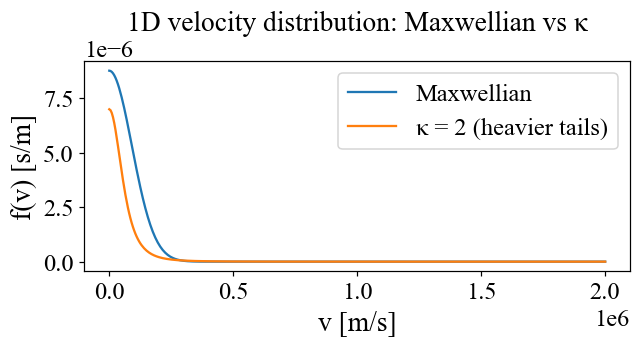

In [41]:
import numpy as np, astropy.units as u, matplotlib.pyplot as plt
from plasmapy.formulary.distribution import Maxwellian_speed_1D, kappa_velocity_1D

T = 1e6 * u.K; m = 1 * u.u
vv = np.linspace(0, 2e6, 400) * u.m / u.s
f_mw = Maxwellian_speed_1D(vv, T, m)
f_k  = kappa_velocity_1D(vv, T, particle=m, kappa=2)

plt.figure(figsize=(6, 3.5))
plt.plot(vv, f_mw, label="Maxwellian")
plt.plot(vv, f_k, label="κ = 2 (heavier tails)")
plt.xlabel("v [m/s]"); plt.ylabel("f(v) [s/m]")
plt.title("1D velocity distribution: Maxwellian vs κ")
plt.legend(); plt.tight_layout(); plt.show()

### §40 库仑碰撞：截断参数、平均自由程、约化质量与迁移率

`plasmapy.formulary.collisions`（及子模块）提供微观碰撞量：

| 量 | 公式 | PlasmaPy 函数 |
|---|---|---|
| 垂直碰撞参数 | $\displaystyle b_{\perp}=\frac{Z_{1}Z_{2}e^{2}}{4\pi\varepsilon_{0}\,\mu\,v^{2}}$ | `impact_parameter_perp(T, species, V)` |
| 平均自由程 | $\displaystyle \lambda_{mfp}=\frac{v}{\nu_{ii}}$ | `mean_free_path(T, n_e, species)` |
| 约化质量 | $\displaystyle \mu_{12}=\frac{m_{1}m_{2}}{m_{1}+m_{2}}$ | `reduced_mass(particle1, particle2)` |
| 库仑对数 | $\displaystyle \ln\Lambda=\frac{1}{2}\ln\!\left(1+\frac{b_{max}^{2}}{b_{min}^{2}}\right)$ | `Coulomb_logarithm(T, n_e, species)` |
| 迁移率 | $\displaystyle \mu=\frac{e}{m\,\nu}$ | `mobility(T, n_e, species)` |

In [42]:
from plasmapy.formulary.collisions.lengths import impact_parameter_perp, mean_free_path
from plasmapy.formulary.collisions.misc import reduced_mass, mobility
from plasmapy.formulary.collisions import Coulomb_logarithm
import astropy.units as u

T = 1e6 * u.K
n = 1e19 * u.m**-3
V = 1e6 * u.m / u.s
print("impact_parameter_perp :", impact_parameter_perp(T, ('p+', 'e-'), V=V))
print("mean_free_path        :", mean_free_path(T, n, ('p+', 'e-')))
print("reduced_mass(p+, e-)   :", reduced_mass('p+', 'e-'))
print("Coulomb_logarithm      :", Coulomb_logarithm(T, n, ('p+', 'e-')))
print("mobility              :", mobility(T, n, ('e-', 'p+')))

impact_parameter_perp : 2.5340177743968807e-10 m
mean_free_path        : 7.839514845912268 m
reduced_mass(p+, e-)   : 9.10442528891677e-31 kg
Coulomb_logarithm      : 14.54552755767675


mobility              : 250505.1583712107 m2 / (V s)


### §41 无量纲数、耦合与简并参数

`plasmapy.formulary.dimensionless` 与 `...collisions.dimensionless`、`...quantum` 提供无量纲判据：

| 量 | 公式 | PlasmaPy 函数 |
|---|---|---|
| 库仑耦合参数 | $\displaystyle \Gamma=\frac{Z^{2}e^{2}}{4\pi\varepsilon_{0}a k_{B}T}$ | `coupling_parameter` |
| 克努森数 | $\displaystyle Kn=\frac{\lambda_{mfp}}{L}$ | `Knudsen_number` |
| Wigner–Seitz 半径 | $\displaystyle a=\left(\frac{3}{4\pi n}\right)^{1/3}$ | `Wigner_Seitz_radius` |
| 热德布罗意波长 | $\displaystyle \lambda_{dB}^{th}=\frac{h}{\sqrt{2\pi m k_{B}T}}$ | `thermal_deBroglie_wavelength` |
| 化学势 | $\displaystyle \mu=k_{B}T\ln(n\lambda_{dB}^{3})$ | `chemical_potential` |
| 德拜数 | $\displaystyle N_{D}=\frac{4\pi n\lambda_{D}^{3}}{3}$ | `Debye_number` |
| 等离子体 β | $\displaystyle \beta=\frac{2\mu_{0}n k_{B}T}{B^{2}}$ | `beta` |
| 霍尔参数 | $\displaystyle \beta_{H}=\omega_{c}\tau$ | `Hall_parameter` |
| 伦德奎斯特数 | $\displaystyle S=\frac{L v_{A}}{\eta}$ | `Lundquist_number` |
| 磁雷诺数 | $\displaystyle R_{m}=\mu_{0}\sigma L v$ | `Mag_Reynolds` |
| 雷诺数 | $\displaystyle Re=\frac{\rho U L}{\mu}$ | `Reynolds_number` |
| 简并温度比 | $\displaystyle \Theta=\frac{T}{T_{F}}$ | `quantum_theta` |
| 托马斯–费米长度 | $\displaystyle a_{TF}\propto Z^{-1/3}a_{0}$ | `Thomas_Fermi_length` |
| 德布罗意波长 | $\displaystyle \lambda_{dB}=\frac{h}{m v}$ | `deBroglie_wavelength` |
| 费米能 | $\displaystyle E_{F}=\frac{\hbar^{2}}{2m}(3\pi^{2}n)^{2/3}$ | `Fermi_energy` |
| 费米积分 | $\displaystyle F_{j}(\eta)=\int_{0}^{\infty}\frac{x^{j}}{1+e^{x-\eta}}dx$ | `Fermi_integral` |

> 伦德奎斯特数用 `Spitzer_resistivity` 电导率 $\sigma=1/\eta$ 作为电导率输入。

In [43]:
from plasmapy.formulary.dimensionless import (Hall_parameter, Lundquist_number,
    Mag_Reynolds, Reynolds_number, beta, Debye_number, quantum_theta)
from plasmapy.formulary.collisions.dimensionless import (Knudsen_number, Wigner_Seitz_radius,
    thermal_deBroglie_wavelength, chemical_potential, coupling_parameter)
from plasmapy.formulary.quantum import Thomas_Fermi_length, deBroglie_wavelength, Fermi_energy
from plasmapy.formulary.mathematics import Fermi_integral
from plasmapy.formulary.collisions import Spitzer_resistivity
import astropy.units as u

T = 1e6 * u.K; n = 1e19 * u.m**-3; B = 1 * u.T; L = 1 * u.m
print("coupling_parameter :", coupling_parameter(T, n, ('e-', 'p+')))
print("Knudsen_number     :", Knudsen_number(L, T, n, ('e-', 'p+')))
print("Wigner_Seitz_radius:", Wigner_Seitz_radius(n))
print("thermal_deBroglie  :", thermal_deBroglie_wavelength(T))
print("chemical_potential :", chemical_potential(n, T))
print("Debye_number       :", Debye_number(T, n))
print("beta               :", beta(T, n, B))
print("Hall_parameter     :", Hall_parameter(n, T, B, 'p+', 'e-'))
sigma = 1.0 / Spitzer_resistivity(T, n, ('e-', 'p+'))
print("Lundquist_number   :", Lundquist_number(L, B, n, sigma, ion='p+'))
print("Mag_Reynolds       :", Mag_Reynolds(1e3 * u.m / u.s, L, sigma))
print("Reynolds_number    :", Reynolds_number(1e-3 * u.kg / u.m**3, 1e3 * u.m / u.s, L, 1e-3 * u.kg / (u.m * u.s)))
print("quantum_theta      :", quantum_theta(T, n))
print("Thomas_Fermi_length:", Thomas_Fermi_length(n))
print("deBroglie_wavelength:", deBroglie_wavelength(1e6 * u.m / u.s, 'e-'))
print("Fermi_energy       :", Fermi_energy(n))
print("Fermi_integral(0.5,2):", Fermi_integral(0.5, 2))

coupling_parameter : 5.803301226842571e-05
Knudsen_number     : 7.839514845912268
Wigner_Seitz_radius: 2.879411911484863e-07 m
thermal_deBroglie  : 7.453838105430501e-11 m


chemical_potential : 0.0
Debye_number       : 435316.81940333045
beta               : 0.00034699494040107287
Hall_parameter     : 332825.36211267125
Lundquist_number   : 3477882.267634283
Mag_Reynolds       : 504.35569714487826
Reynolds_number    : 1000.0
quantum_theta      : 50913851.59520307
Thomas_Fermi_length: 2.4971349149210714e-09 m
deBroglie_wavelength: 7.273854626740759e-10 m
Fermi_energy       : 2.711735523324816e-25 J
Fermi_integral(0.5,2): (1.4104846112497242-0j)


### §42 低频混合频率与相对论性检验

| 量 | 公式 | PlasmaPy 函数 |
|---|---|---|
| 双离子 Buchsbaum 频率 | $\displaystyle \omega_{BH}^{2}=\frac{\omega_{ci}^{2}\omega_{cj}^{2}}{\omega_{ci}^{2}+\omega_{cj}^{2}}$ | `Buchsbaum_frequency` |
| 下混杂频率 | $\displaystyle \omega_{LH}^{2}=\frac{\omega_{ci}^{2}+\omega_{pi}^{2}}{1+\omega_{pe}^{2}/\omega_{ce}^{2}}$ | `lower_hybrid_frequency` |
| 上混杂频率 | $\displaystyle \omega_{UH}^{2}=\omega_{pe}^{2}+\omega_{ce}^{2}$ | `upper_hybrid_frequency` |
| 相对论检验 | $\displaystyle \gamma=\frac{1}{\sqrt{1-v^{2}/c^{2}}}$，$v\gtrsim 0.1c$ 报警 | `check_relativistic` |

频率函数均支持 `to_hz=True` 直接返回 Hz（内部经 `angular_freq_to_hz` 装饰器转换）。

In [44]:
from plasmapy.formulary.frequencies import (Buchsbaum_frequency, lower_hybrid_frequency,
    upper_hybrid_frequency)
from plasmapy.formulary.speeds import check_relativistic, thermal_speed_coefficients
import astropy.units as u

B = 1 * u.T; n = 1e19 * u.m**-3
print("Buchsbaum_frequency:", Buchsbaum_frequency(B, n, n, 'p+', 'He-4++'))
print("lower_hybrid (rad) :", lower_hybrid_frequency(B, n, 'p+'))
print("lower_hybrid (Hz)  :", lower_hybrid_frequency(B, n, 'p+', to_hz=True))
print("upper_hybrid (Hz)  :", upper_hybrid_frequency(B, n, to_hz=True))

# check_relativistic 是装饰器：当被装饰函数返回的速率 v 满足 β = v/c ≥ betafrac 时报警
@check_relativistic
def v_sub():
    return 1e6 * u.m / u.s          # β ≈ 0.0033 < 5% → 无报警

@check_relativistic(betafrac=0.01)
def v_rel():
    return 1e7 * u.m / u.s          # β ≈ 0.033 > 1% → 触发 RelativityWarning

print("check_relativistic (sub)  :", v_sub())
print("check_relativistic (rel)   :", v_rel())
print("thermal_speed_coef (3D, mp):", thermal_speed_coefficients('most_probable', 3))

Buchsbaum_frequency: 75909647.5451258 rad / s
lower_hybrid (rad) : 2922908075.198838 rad / s
lower_hybrid (Hz)  : 465195268.37111247 Hz
upper_hybrid (Hz)  : 39871585696.02871 Hz
check_relativistic (sub)  : 1000000.0 m / s
check_relativistic (rel)   : 10000000.0 m / s
thermal_speed_coef (3D, mp): 1.4142135623730951


E:\PhySimX\PhySimX\simulation\PlasmaPy\PlasmaPy\PlasmaPy\src\plasmapy\utils\decorators\checks.py:1396: RelativityWarning: v_rel is yielding a velocity that is 3.336% of the speed of light. Relativistic effects may be important.
  warnings.warn(


### §43 辐射输运：自由-自由韧致辐射与辐射转移框架（`plasmapy.formulary.radiation`）

PlasmaPy 2026.2.0 的辐射专用 API 为 `thermal_bremsstrahlung`（体积发射率 $j_\nu^{\rm ff}$），其本身仅在瑞利-金斯近似 $\hbar\omega\ll k_BT_e$ 下成立；由此可借助基尔霍夫定律搭建完整的辐射转移框架。

**自由-自由体积发射率**（PlasmaPy `thermal_bremsstrahlung`）：

$$j_\nu^{\rm ff}\simeq \frac{1}{6\pi\sqrt{3}}\frac{e^6}{m_e c^3}\frac{n_e n_i Z^2}{\sqrt{2\pi m_e k_B T_e}}\,\bar g_{\rm ff}\,e^{-\hbar\omega/(k_B T_e)}$$

R-J 极限下 $\bar g_{\rm ff}\approx 1$，发射率近似与频率无关（以下代码将验证）。

**局域热动平衡（基尔霍夫定律）与吸收系数**：

$$j_\nu=\alpha_\nu B_\nu,\qquad \alpha_\nu=\frac{j_\nu}{B_\nu}$$

**普朗克平衡源函数（谱辐射亮度）**：

$$B_\nu(T)=\frac{2h\nu^3}{c^2}\frac{1}{\exp(h\nu/k_BT)-1}$$

**辐射转移方程与光深**：

$$\frac{dI_\nu}{ds}=-\alpha_\nu I_\nu+j_\nu,\qquad \tau_\nu=\int_0^L\alpha_\nu\,ds,\qquad I_\nu(L)=I_{\nu,0}e^{-\tau_\nu}+B_\nu(1-e^{-\tau_\nu})$$

**汤姆逊电子散射不透明度**：

$$\kappa_{\rm es}=n_e\sigma_T$$

**黑体辐射场宏观量（Stefan–Boltzmann）**：

$$u_{\rm rad}=aT^4=\frac{4\sigma_{\rm SB}}{c}T^4,\qquad P_{\rm rad}=\frac{u_{\rm rad}}{3},\qquad F=\sigma_{\rm SB}T^4$$

**相对论同步辐射（俯仰角平均总功率）**：

$$P_{\rm sync}=\frac{4}{3}\sigma_T c\,\beta^2\gamma^2 U_B,\qquad U_B=\frac{B^2}{2\mu_0},\qquad \nu_c\simeq\gamma^2\nu_{ce}$$

emissivity j_nu unit    : kg / (m s2)
R-J parameter max h*nu/(k_B T_e) = 0.048 (must be < 0.1)
j_nu flat? min/max      : 1.858e-13 7.384e-13


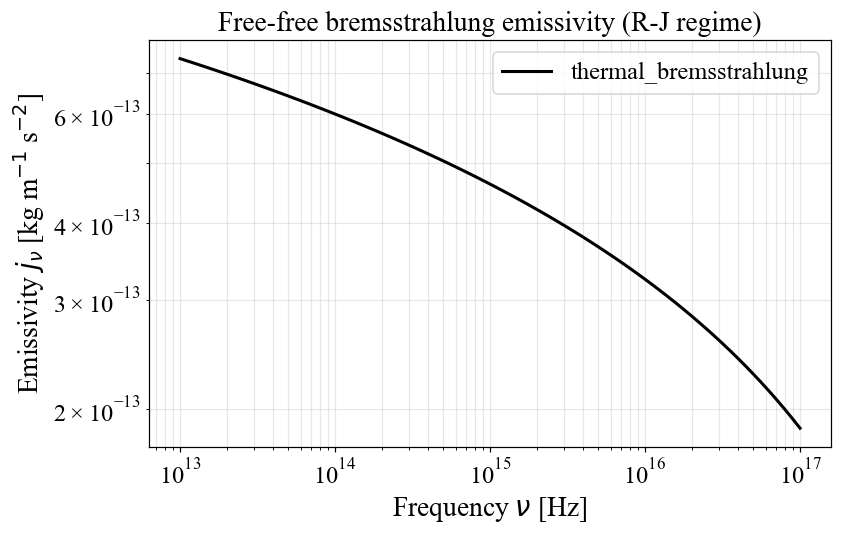

In [45]:
from plasmapy.formulary.radiation import thermal_bremsstrahlung
from astropy.constants import h

n_e = 1e21 * u.m**-3      # electron density
T_e = 1e8  * u.K          # electron temperature (R-J regime requires h*nu << k_B*T_e)
n_i = 1e21 * u.m**-3      # ion density (fully ionized H)
nu  = np.logspace(13, 17, 80) * u.Hz

# PlasmaPy free-free volumetric emissivity j_nu (units: kg m^-1 s^-2)
j_ff = thermal_bremsstrahlung(nu, n_e, T_e, n_i=n_i, ion='p+')
rj_max = (h * nu.max() / (k_B * T_e)).to_value(u.dimensionless_unscaled)
print("emissivity j_nu unit    :", j_ff.unit)
print("R-J parameter max h*nu/(k_B T_e) =", f"{rj_max:.3f}", "(must be < 0.1)")
print("j_nu flat? min/max      :", f"{j_ff.value.min():.3e}", f"{j_ff.value.max():.3e}")

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.loglog(nu, j_ff, 'k-', lw=2, label='thermal_bremsstrahlung')
ax.set_xlabel(r'Frequency $\nu$ [Hz]')
ax.set_ylabel(r'Emissivity $j_\nu$ [kg m$^{-1}$ s$^{-2}$]')
ax.set_title('Free-free bremsstrahlung emissivity (R-J regime)')
ax.legend(); ax.grid(True, which='both', alpha=0.3)

B_nu    unit: Hz3 s3 J / m2
alpha_nu unit: 1 / m  tau range: 6.20e-19 2.40e-10
kappa_es (Thomson) : 6.6524587051e-08 1 / m
u_rad : 7.565733250280008e+16 J / m3  | P_rad : 2.5219110834266692e+16 Pa  | F_rad : 5.670374419184432e+24 W / m2
nu_ce (electron gyro): 27992489834.22872 Hz
P_sync : 1.0474588292451828e-12 J / s  | nu_c ~ 2799248983422.872 Hz


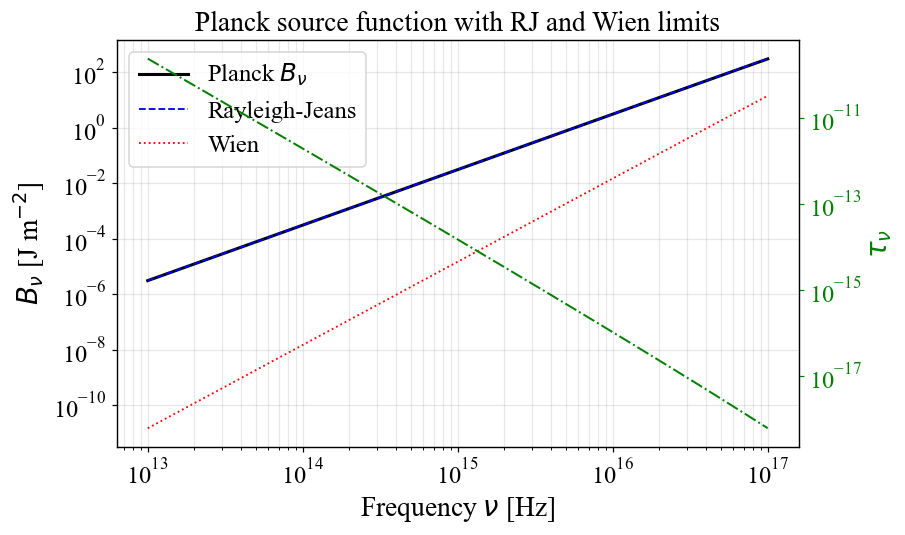

In [46]:
from astropy.constants import h, sigma_sb, sigma_T
from plasmapy.formulary.frequencies import gyrofrequency

# --- Planck equilibrium source function B_nu (exact) ---
B_nu = (2 * h * nu**3 / c**2) / (np.exp((h * nu) / (k_B * T_e)) - 1)

# --- Kirchhoff law: absorption coefficient and optical depth ---
alpha_nu = (j_ff / B_nu).to(1 / u.m)          # per-frequency absorption coefficient
L = 1e-3 * u.m                                # path length
tau_nu = (alpha_nu * L).to(u.dimensionless_unscaled)

# --- Thomson electron-scattering opacity ---
kappa_es = (n_e * sigma_T).to(1 / u.m)

# --- Macroscopic blackbody radiation quantities (Stefan-Boltzmann) ---
u_rad = (4 * sigma_sb / c * T_e**4).to(u.J / u.m**3)   # radiation energy density
P_rad = (u_rad / 3).to(u.Pa)                            # radiation pressure
F_rad = (sigma_sb * T_e**4).to(u.W / u.m**2)            # blackbody flux

# --- Relativistic synchrotron (pitch-angle averaged) total power ---
B = 1 * u.T
nu_ce = gyrofrequency(B, 'e-', to_hz=True)             # electron gyrofrequency [Hz]
gamma = 10.0
beta = np.sqrt(1 - 1 / gamma**2)
U_B = (B**2 / (2 * mu0)).to(u.J / u.m**3)              # magnetic energy density
P_sync = (4 / 3) * sigma_T * c * beta**2 * gamma**2 * U_B
nu_c = gamma**2 * nu_ce                                 # characteristic synchrotron freq

print("B_nu    unit:", B_nu.unit)
print("alpha_nu unit:", alpha_nu.unit, " tau range:", f"{tau_nu.value.min():.2e}", f"{tau_nu.value.max():.2e}")
print("kappa_es (Thomson) :", kappa_es)
print("u_rad :", u_rad, " | P_rad :", P_rad, " | F_rad :", F_rad)
print("nu_ce (electron gyro):", nu_ce)
print("P_sync :", P_sync, " | nu_c ~", nu_c.to(u.Hz))

# --- plot Planck source function with RJ and Wien asymptotes, + optical depth on twin axis ---
B_RJ   = (2 * k_B * T_e / c**2) * nu**2
B_Wien = (2 * h * nu**3 / c**2) * np.exp(-(h * nu) / (k_B * T_e))
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.loglog(nu, B_nu.to(u.J / u.m**2), 'k-', lw=2, label='Planck $B_\\nu$')
ax.loglog(nu, B_RJ.to(u.J / u.m**2), 'b--', lw=1.2, label='Rayleigh-Jeans')
ax.loglog(nu, B_Wien.to(u.J / u.m**2), 'r:', lw=1.2, label='Wien')
ax.set_xlabel(r'Frequency $\nu$ [Hz]')
ax.set_ylabel(r'$B_\nu$ [J m$^{-2}$]')
ax.set_title('Planck source function with RJ and Wien limits')
ax.legend(loc='upper left'); ax.grid(True, which='both', alpha=0.3)
ax2 = ax.twinx()
ax2.loglog(nu, tau_nu.value, 'g-.', lw=1.3, label=r'optical depth $\tau_\nu$ (L=1 mm)')
ax2.set_ylabel(r'$\tau_\nu$', color='g')
ax2.tick_params(axis='y', colors='g')

### §44 结论与版本提示

本 Notebook 用**公式 + 可运行代码**覆盖 PlasmaPy 2026.2.0 的核心 API，按 7 篇 + 补充组织：

- **Part 0–I**：单位/粒子/原子数据、特征频率/长度/速度/密度/介电
- **Part II**：麦克斯韦 & κ 分布、激光与临界密度、量子简并、韧致辐射、相对论
- **Part III**：库仑碰撞、Braginskii 输运、电离平衡、无量纲数
- **Part IV**：色散函数 $Z(\zeta)$、Stix / two-fluid / MHD 波
- **Part V**：Harris/无力平衡、CartesianGrid、静磁场源、ParticleTracker、CFL
- **Part VI**：汤姆逊/朗缪尔/射线照相/磁零点诊断
- **Part VII**：`_lite` 性能、`particle_input` 与异常
- **Part VIII（补充代码）**：数学/积分工具、拟合函数、粒子核数据、磁场压力与 Bohm 扩散、Braginskii 输运系数与 Bethe 阻止本领
- **Part IX（新增代码）**：§38 漂移速度、§39 麦克斯韦/κ 分布全族、§40 库仑碰撞（碰撞参数/自由程/约化质量/迁移率/库仑对数）、§41 无量纲数·耦合·简并参数、§42 混合频率与相对论检验
- **Part X（辐射输运）**：§43 `thermal_bremsstrahlung` 自由-自由发射率、基尔霍夫定律→吸收系数→光深、普朗克源函数（R-J/Wien 极限）、汤姆逊散射不透明度、黑体辐射压/能量密度/总流、相对论同步辐射功率

> 数值均按安装版本实测核对；升级版本后请重跑 `docs/verify/verify_guide_api.py` 复验 API。
> 本 Notebook 作为《PlasmaPy详细使用指南.md》的可执行替代文档。